# **Final Project of the Course: Data Processing, Analysis, and Visualization - 88-6970-01**

**Name:  Noa Klein ID: 213902034**

**Name: Shani Nadav ID: 213063399**


#טעינת הנתונים וייבוא ספריות

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import shapiro
from scipy.stats import pearsonr
from scipy.stats import norm
import numpy as np
import math
import itertools
import pandas as pd
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("train-2.csv")
df.head()


Saving train-2.csv to train-2.csv


,id,Name,Event_Number,Event_Length_minutes,Genre,Host_Popularity_percentage,Event_Day,Publication_Time,Guest_Popularity_percentage,Number_of_Sponsers,Event_Sentiment,Watch_Time_minutes
0,0,Mystery Matters,Episode 98,NaN,True Crime,74.81,Thursday,Night,NaN,0.0,Positive,31.41998
1,1,Joke Junction,Episode 26,119.80,Comedy,66.95,Saturday,Afternoon,75.95,2.0,Negative,88.01241
2,2,Study Sessions,Episode 16,73.90,Education,69.97,Tuesday,Evening,8.97,0.0,Negative,44.92531
3,3,Digital Digest,Episode 45,67.17,Technology,57.22,Monday,Morning,78.70,2.0,Positive,46.27824
4,4,Mind & Body,Episode 86,110.51,Health,80.07,Monday,Afternoon,58.68,3.0,Neutral,75.61031


#סטטיסטיקות כלליות על הדאטא


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           750000 non-null  int64  
 1   Name                         750000 non-null  object 
 2   Event_Number                 750000 non-null  object 
 3   Event_Length_minutes         662907 non-null  float64
 4   Genre                        750000 non-null  object 
 5   Host_Popularity_percentage   750000 non-null  float64
 6   Event_Day                    750000 non-null  object 
 7   Publication_Time             750000 non-null  object 
 8   Guest_Popularity_percentage  603970 non-null  float64
 9   Number_of_Sponsers           749999 non-null  float64
 10  Event_Sentiment              750000 non-null  object 
 11  Watch_Time_minutes           750000 non-null  float64
dtypes: float64(5), int64(1), object(6)
memory usage: 68.7+ MB


In [ ]:
df.head()

,id,Name,Event_Number,Event_Length_minutes,Genre,Host_Popularity_percentage,Event_Day,Publication_Time,Guest_Popularity_percentage,Number_of_Sponsers,Event_Sentiment,Watch_Time_minutes
0,0,Mystery Matters,Episode 98,NaN,True Crime,74.81,Thursday,Night,NaN,0.0,Positive,31.41998
1,1,Joke Junction,Episode 26,119.80,Comedy,66.95,Saturday,Afternoon,75.95,2.0,Negative,88.01241
2,2,Study Sessions,Episode 16,73.90,Education,69.97,Tuesday,Evening,8.97,0.0,Negative,44.92531
3,3,Digital Digest,Episode 45,67.17,Technology,57.22,Monday,Morning,78.70,2.0,Positive,46.27824
4,4,Mind & Body,Episode 86,110.51,Health,80.07,Monday,Afternoon,58.68,3.0,Neutral,75.61031


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,750000.0,374999.500000,216506.495284,0.0,187499.75000,374999.50000,562499.25000,749999.00
Event_Length_minutes,662907.0,64.504738,32.969603,0.0,35.73000,63.84000,94.07000,325.24
Host_Popularity_percentage,750000.0,59.859901,22.873098,1.3,39.41000,60.05000,79.53000,119.46
Guest_Popularity_percentage,603970.0,52.236449,28.451241,0.0,28.38000,53.58000,76.60000,119.91
Number_of_Sponsers,749999.0,1.348855,1.151130,0.0,0.00000,1.00000,2.00000,103.91
Watch_Time_minutes,750000.0,45.437406,27.138306,0.0,23.17835,43.37946,64.81158,119.97


In [ ]:
print(df.shape)

(750000, 12)


### סיכום

The dataset contains 750,000 rows and 12 variables (using the shape command).

We displayed all feature names using the columns command.

The dataset includes both numerical and categorical variables:
- Numerical variables: Event_Length_minutes, Host_Popularity_percentage, Guest_Popularity_percentage, Number_of_Sponsers, Watch_Time_minutes.
- Categorical variables: Name, Event_Number, Genre, Event_Day, Publication_Time, Event_Sentiment.

Using the info() command, we observed that most variables are complete, however:
- Guest_Popularity_percentage contains approximately 19% missing values.
- Event_Length_minutes contains approximately 11% missing values.
- All other variables contain almost no missing values.

Using the describe() command, we calculated the mean, median, minimum, maximum, and standard deviation for all numerical variables.

From the statistical summary, we observed several important findings:
- The target variable Watch_Time_minutes has an average of approximately 45 minutes and a median of approximately 43 minutes, suggesting a slightly right-skewed distribution.
- Host_Popularity_percentage and Guest_Popularity_percentage contain values above 100%, which may indicate outliers or data quality issues.
- Number_of_Sponsers includes very large values (above 100) and non-integer values, which may require cleaning.
- Event_Length_minutes contains some very long episodes (up to approximately 325 minutes), which should be examined for potential outliers.

Additionally, we displayed the first few rows of the dataset (using the head() command) to better understand the structure and format of the data.

# סוגי משתנים

###מציאת כמות המשתנים הקטגוריאליים והנומריים




To determine the type of each variable, we used a classification method based on data types (dtypes) and the functional nature of the features.

First, variables containing text or labels were identified as categorical variables. These represent distinct groups or categories, such as "Genre", "Event_Day", and "Event_Sentiment".

Second, variables containing numeric values (integers or floats) were classified as numerical variables. These represent measurable quantities, such as "Watch_Time_minutes" and "Host_Popularity_percentage".

Finally, unique identifiers, such as the id column, were treated as index markers and excluded from the statistical analysis of the features.

In [ ]:
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

numerical_features = df.select_dtypes(include=['number']).columns.tolist()

if 'id' in numerical_features:
    numerical_features.remove('id')

print(f"Number of categorical features: {len(categorical_features)}")
print(f"Categorical features: {categorical_features}")

print(f"\nNumber of numerical features: {len(numerical_features)}")
print(f"Numerical features: {numerical_features}")

Number of categorical features: 6
Categorical features: ['Name', 'Event_Number', 'Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment']

Number of numerical features: 5
Numerical features: ['Event_Length_minutes', 'Host_Popularity_percentage', 'Guest_Popularity_percentage', 'Number_of_Sponsers', 'Watch_Time_minutes']


 We discoverd that there are 5 numerical variables and 6 categorical variable.

#תאור המשתנים הקטגוריאליים

###תאור מילולי

To describe the categorical variables, we first explained the meaning of each feature in words.

1. **Name**: Represents the brand or the title of the podcast.


2. **Genre**: Classifies the content into thematic categories (such as Comedy, True Crime, or Technology).

1.  **Event_Number**: Indicates the sequential identifier of the event. it helps track the position of the content within its podcast.

2.  **Event_Day**: The day of the week the content was published. This allows for analyzing audience habits on weekdays versus weekends.


1.   **Publication_Time**: Divides the day into time slots (Morning, Afternoon, Evening, Night) to identify when the audience is most active.

2.   **Event_Sentiment**: Describes the overall tone of the event (Positive, Negative, or Neutral), providing insight into the emotional atmosphere of the content.














###תאור גרפי

 Then, we analyzed their distribution and visualized the results using a histogram.

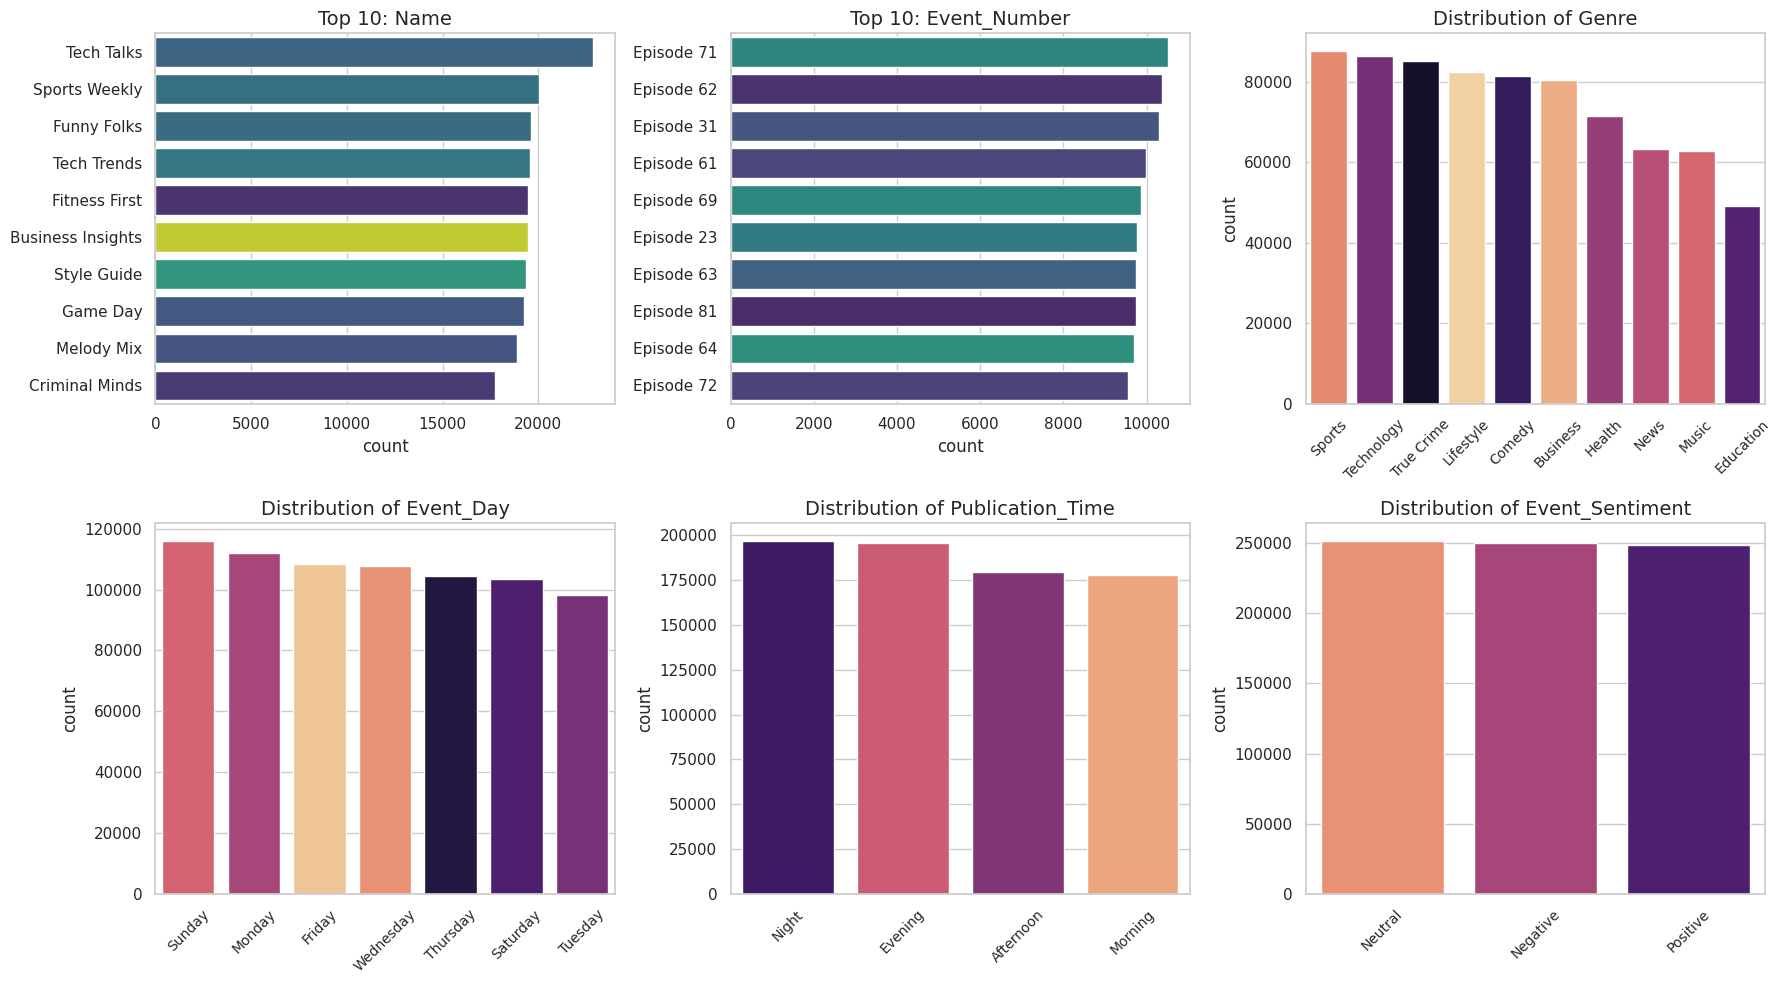

In [ ]:

sns.set_theme(style="whitegrid")

cat_vars = ['Name', 'Event_Number', 'Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment']

plt.figure(figsize=(18, 10))

for i, col in enumerate(cat_vars, 1):
    ax = plt.subplot(2, 3, i)

    if col in ['Name', 'Event_Number']:
        top_10 = df[col].value_counts().iloc[:10].index
        sns.countplot(data=df, y=col, order=top_10, palette='viridis', hue=col)
        plt.title(f'Top 10: {col}', fontsize=14)
        plt.ylabel('')
    else:
        order = df[col].value_counts().index
        sns.countplot(data=df, x=col, order=order, palette='magma', hue=col)
        plt.xticks(rotation=45, fontsize=10)
        plt.title(f'Distribution of {col}', fontsize=14)
        plt.xlabel('')

    if ax.get_legend():
        ax.get_legend().remove()

plt.tight_layout()
plt.show()

To analyze the distribution of the categorical variables, we performed a frequency analysis to understand the occurrence of each category across the 750,000 records. We visualized these distributions using count plots, organized into a grid to allow for a comparative overview of the content trends. Below are the specific descriptions for each graph:

  - Name (Top 10): Displays the top 10 shows (podcasts) that appear most frequently in the dataset. A horizontal bar chart was used to ensure the names are legible.

 - Event_Number (Top 10): Displays the most common episode numbers. This helps identify if there is a high concentration of specific episodes (e.g., premiere episodes).

 - Genre: Shows the distribution of various genres, allowing us to identify which content category is the most dominant.

 - Event_Day: Displays the days of the week on which the content was published, helping to identify scheduling patterns.

 - Publication_Time: Shows the distribution of publications across different times of the day (Morning, Afternoon, Evening, Night).

 - Event_Sentiment: Displays the emotional analysis of the content (Positive, Negative, or Neutral) to characterize the overall tone of the dataset.

During the categorical data analysis, we utilized the value_counts command to identify 'categorical outliers' values that appear with very low frequency compared to the rest of the dataset. We found that for variables such as Name and Event_Number, the large number of rare categories created visual 'noise' that made the charts unreadable. To address this, we applied a filtering approach to focus on the core data (the Top 10) and exclude these minor outliers from the visualization. This allowed us to highlight the most significant trends while maintaining clarity and focus in our results

In [ ]:
print(f"Unique names: {df['Name'].nunique()}")
print(f"Unique episode numbers: {df['Event_Number'].nunique()}")

name_counts = df['Name'].value_counts()

print("--- Top 5 Names ---")
print(name_counts.head(10))

print("\n--- Bottom 5 Names (The 'Outliers') ---")
print(name_counts.tail(10))


top_10_names = df['Name'].value_counts().iloc[:10].index
print(f"\nSelected Top 10 for visualization: {list(top_10_names)}")

Unique names: 48
Unique episode numbers: 100
--- Top 5 Names ---
Name
Tech Talks           22847
Sports Weekly        20053
Funny Folks          19635
Tech Trends          19549
Fitness First        19488
Business Insights    19480
Style Guide          19364
Game Day             19272
Melody Mix           18889
Criminal Minds       17735
Name: count, dtype: int64

--- Bottom 5 Names (The 'Outliers') ---
Name
Market Masters         13092
Study Sessions         13053
Innovators             12913
Music Matters          12652
Learning Lab           12291
Educational Nuggets    12245
Healthy Living         12198
Brain Boost            11543
Health Hour            11114
News Roundup            9169
Name: count, dtype: int64

Selected Top 10 for visualization: ['Tech Talks', 'Sports Weekly', 'Funny Folks', 'Tech Trends', 'Fitness First', 'Business Insights', 'Style Guide', 'Game Day', 'Melody Mix', 'Criminal Minds']


Visual Density: We discovered that the Name column contains 48 unique values, while the Event_Number column has 100. Displaying 100 bars in a single chart would make it impossible to read the labels.

The "Top 10" Conclusion: By comparing the head (the most frequent values) with the tail (the rare values), we observed that the top ten categories concentrate the bulk of the significant data. Therefore, filtering for the Top 10 is the most professional way to "clean" the graph and retain only the information that truly provides insight into the dataset.

#תאור המשתנים הנומריים

###תאור מילולי

To describe the numerical variables, we will first explain the meaning of each feature in words. Then, we will analyze their distribution and visualize the results and show a histogram.

1. **Event_Length_minutes:** The total duration of the episode or event in minutes
2. **Host_Popularity_percentage**: A percentage representing how well-known or liked the host is by the audience.
3. **Guest_Popularity_percentage:** A percentage representing the fame or popularity level of the guest featured in the episode.
4. **Number_of_Sponsers:** The total count of commercial sponsorships within a single episode
1.   **Watch_Time_minutes:** The cumulative number of minutes the audience spent watching or listening to the episode




###תאור גרפי

 Then, we analyzed their distribution and visualized the results using a histogram.

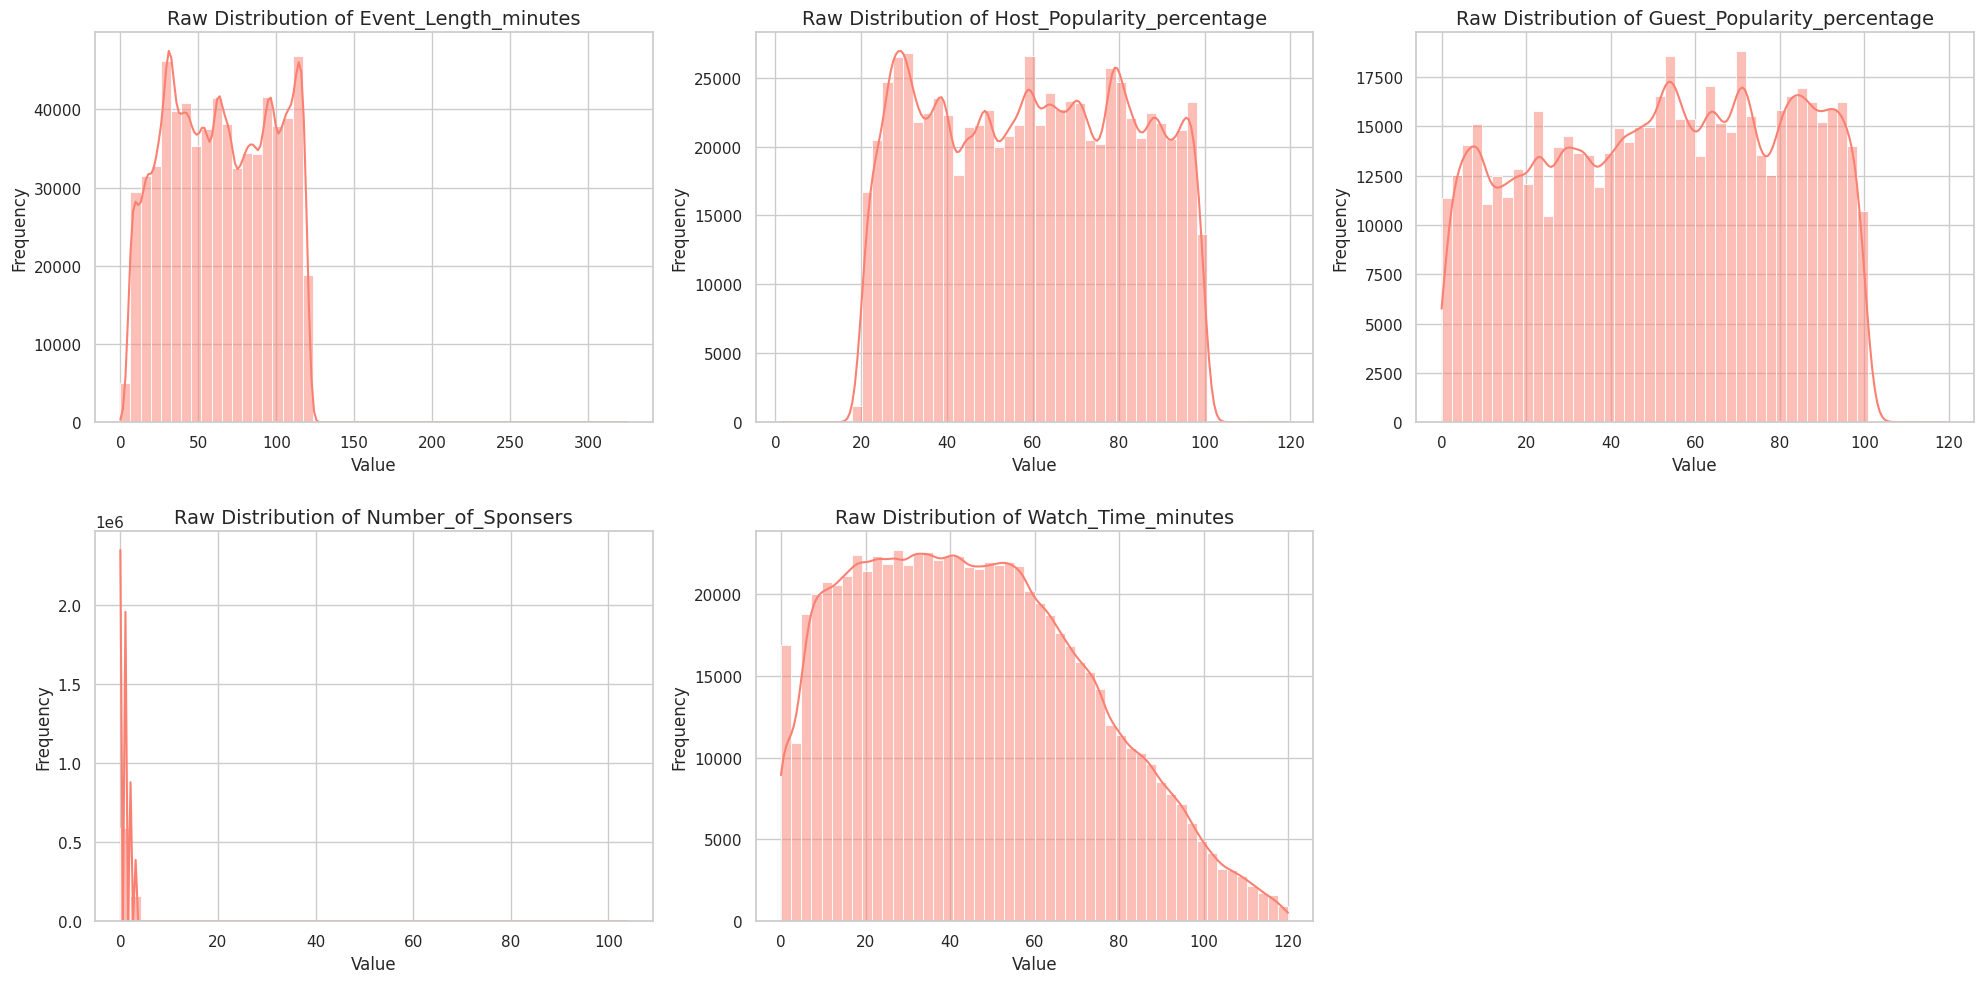

In [ ]:


sns.set_theme(style="whitegrid")

num_vars = ['Event_Length_minutes', 'Host_Popularity_percentage', 'Guest_Popularity_percentage', 'Number_of_Sponsers', 'Watch_Time_minutes']

plt.figure(figsize=(20, 10))

for i, col in enumerate(num_vars, 1):
    plt.subplot(2, 3, i)

    sns.histplot(df[col], kde=True, color='salmon', bins=50)

    plt.title(f'Raw Distribution of {col}', fontsize=14)
    plt.xlabel('Value')
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

For the numerical variables, we deliberately opted to visualize the Raw Data without applying any outlier removal filters. This approach highlights the following:

Outlier Visibility: The lack of perfect centering in the histograms is a direct result of extreme outliers. These values stretch the X-axis, forcing the majority of the data to appear compressed on one side.

Distribution Skewness: By leaving the data 'as is,' we provide a transparent view of the dataset's true variance. The visible 'long tails' represent rare but significant edge cases that would be hidden if the data were artificially centered.
This visualization confirms our initial suspicion regarding the presence of outliers and demonstrates how they influence the overall scale and interpretation of the results

#ערכים חסרים

###איתור ערכים חסרים

Missing values in numerical data can appear as text, NaN, or null. To check the data, we go through all the rows and search for such values.

as we saw in the general statistics part, Using the info() command, we observed that most variables are complete, however:

Guest_Popularity_percentage contains approximately 19% missing values.
Event_Length_minutes contains approximately 11% missing values.
Number_of_Sponsers contains one missing value.
All other variables contain no missing values.

In [ ]:
missing_values_count = df.isnull().sum()
print("missing values:")
print(missing_values_count[missing_values_count > 0])

missing values:
Event_Length_minutes            87093
Guest_Popularity_percentage    146030
Number_of_Sponsers                  1
dtype: int64


we confirmed the presence of missing values in the three variables we identified. we also searched for missing values in those columns to ensure we did not miss any issues.

###טיפול בערכים חסרים

Since our variables are numerical, we will use statistical values to 'guess' the missing information in the least biased way possible:

**For Number_of_Sponsers:**

- The Situation: Only one value is missing.

- The Solution: We will fill it with the Mode – the value that appears most frequently in the data (in our case, 0).

**For Event_Length_minutes:**

- The Situation: The mean and the median are very close to each other (approximately 64 minutes).

- The Solution: We will fill it with the Median. The median is more robust against Outliers that could otherwise distort the mean.

**For Guest_Popularity_percentage:**

- The Situation: About 20% of the data is missing.

- The Solution: We will fill it with the Mean or the Median. Since this represents a percentage, the mean provides a good representation of the 'average guest'.

In [ ]:
sponsors_mode = df['Number_of_Sponsers'].mode()[0]
df['Number_of_Sponsers'] = df['Number_of_Sponsers'].fillna(sponsors_mode)

length_median = df['Event_Length_minutes'].median()
df['Event_Length_minutes'] = df['Event_Length_minutes'].fillna(length_median)

guest_mean = df['Guest_Popularity_percentage'].mean()
df['Guest_Popularity_percentage'] = df['Guest_Popularity_percentage'].fillna(guest_mean)

In [ ]:
print(df[['Number_of_Sponsers', 'Event_Length_minutes', 'Guest_Popularity_percentage']].isnull().sum())

Number_of_Sponsers             0
Event_Length_minutes           0
Guest_Popularity_percentage    0
dtype: int64


no missing values.

#מציאה וטיפול בערכי קיצון קטגוריאליים

###מציאת ערכי קיצון קטגוריאליים

For categorical variables, we looked at the number of values in each category.



In [ ]:
for col in df.columns[:13]:
    print(f'Column: {col}')
    print(df[col].value_counts())
    print("===========================")

Column: id
id
749983    1
749982    1
749981    1
749980    1
749979    1
         ..
4         1
3         1
2         1
1         1
0         1
Name: count, Length: 750000, dtype: int64
Column: Name
Name
Tech Talks             22847
Sports Weekly          20053
Funny Folks            19635
Tech Trends            19549
Fitness First          19488
Business Insights      19480
Style Guide            19364
Game Day               19272
Melody Mix             18889
Criminal Minds         17735
Finance Focus          17628
Detective Diaries      17452
Crime Chronicles       17374
Athlete's Arena        17327
Fashion Forward        17280
Tune Time              17254
Business Briefs        17012
Lifestyle Lounge       16661
True Crime Stories     16373
Sports Central         16191
Digital Digest         16171
Humor Hub              16144
Mystery Matters        16002
Comedy Corner          15927
Joke Junction          15074
Wellness Wave          15009
Sport Spot             14778
Gadget Geek

Below is a concise list of the outliers and data integrity issues identified in the dataset. These points highlight specific cases that require cleaning before proceeding with statistical modeling:

Logical Errors and Extreme Outliers in Number_of_Sponsers:

- The Issue: The column contains decimal values such as 103.25, 53.37, and 103.88.

- Why it's an Outlier: First, the number of sponsors must be an integer (0, 1, 2, etc.); a decimal is a data entry error. Second, while most records fall between 0 and 3, values around 100 are extreme outliers that likely leaked from another column.

Values Exceeding 100% in Popularity Metrics:

- The Issue: In Guest_Popularity_percentage and Host_Popularity_percentage, values like 119.91 and 114.97 appear.

- Why it's an Outlier: Percentage scales should cap at 100. Any value above this is a recording error that distorts the mean and requires "capping" at 100 or removal.

Artificial "Noise" in Guest_Popularity_percentage:

- The Issue: The value 52.236449 appears exactly 146,030 times.

- Why it requires treatment: This is not a natural occurrence but the result of filling missing values with the mean (Imputation). In visualizations, this creates a massive, artificial spike in the center that skews the distribution shape.
- Due to the fact that this value appears with an extremely high frequency compared to the rest of the observations, we expect to see a single, sharp spike in the normalized distribution graph at the mean point, reflecting the artificial concentration of the data.

Suspicious Default Values in Event_Length_minutes:

- The Issue: The value 63.84 appears 87,225 times.

- Why it requires treatment: Similar to the point above, this is likely a "placeholder" or default value inserted by the system when the actual duration was unknown, leading to an unnatural concentration of data at a single point.

Textual Pollution in Event_Number:

- The Issue: All values are prefixed with the string "Episode ".

- Why it requires treatment: While not an outlier in the traditional sense, this is a "structural outlier." The computer cannot perform mathematical calculations on this column because it is identified as text (Object) rather than a number.

Long Tail (Skewness) in Watch_Time_minutes:

- The Issue: There are extreme values on the far right of the graph (watch times significantly higher than the average).

- Why it's an Outlier: These values "stretch" the graph, making the majority of the data appear compressed. This is a classic case for applying the IQR method to focus on the representative distribution of the majority of users.

###נקודות הקיצון הסופיות

We will now address the outliers we identified.

In [ ]:
df = pd.read_csv('train-2.csv')

print("--- Starting Data Cleaning Process ---")


df['Event_Number'] = df['Event_Number'].str.replace('Episode ', '', regex=False).astype(int)
print("Step 1: Event_Number cleaned and converted to integer.")


df['Number_of_Sponsers'] = pd.to_numeric(df['Number_of_Sponsers'], errors='coerce')


typical_median_sponsers = df[df['Number_of_Sponsers'] <= 10]['Number_of_Sponsers'].median()
df['Number_of_Sponsers'] = df['Number_of_Sponsers'].apply(lambda x: round(x) if x <= 10 else typical_median_sponsers)
df['Number_of_Sponsers'] = df['Number_of_Sponsers'].fillna(typical_median_sponsers)
print("Step 2: Sponsors cleaned (decimal errors and extreme outliers removed).")


df['Host_Popularity_percentage'] = df['Host_Popularity_percentage'].clip(upper=100)
df['Guest_Popularity_percentage'] = df['Guest_Popularity_percentage'].clip(upper=100)
print("Step 3: Popularity percentages capped at 100%.")


df['Event_Length_minutes'] = df['Event_Length_minutes'].fillna(df['Event_Length_minutes'].median())
df['Guest_Popularity_percentage'] = df['Guest_Popularity_percentage'].fillna(df['Guest_Popularity_percentage'].median())
print("Step 4: Missing values (NaN) filled using column medians.")


Q1 = df['Watch_Time_minutes'].quantile(0.25)
Q3 = df['Watch_Time_minutes'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

df['Watch_Time_minutes'] = df['Watch_Time_minutes'].clip(upper=upper_bound)
print("Step 5: Watch_Time outliers handled using the IQR method.")

# Export the final cleaned dataset to a new CSV file
df.to_csv('cleaned_data.csv', index=False)

print("\n--- Process Complete! 'cleaned_data.csv' is ready for analysis ---")

--- Starting Data Cleaning Process ---
Step 1: Event_Number cleaned and converted to integer.
Step 2: Sponsors cleaned (decimal errors and extreme outliers removed).
Step 3: Popularity percentages capped at 100%.
Step 4: Missing values (NaN) filled using column medians.
Step 5: Watch_Time outliers handled using the IQR method.

--- Process Complete! 'cleaned_data.csv' is ready for analysis ---


The data is cleaned from outliers.

From this point forward, all analyses and conclusions are based on the 'cleaned_data' file, which has undergone a comprehensive preprocessing phase including outlier treatment, missing value imputation, and data type conversion

In [ ]:
df = pd.read_csv('cleaned_data.csv')

We confirmed that the data is now free of outliers

In [ ]:
for col in df.columns[:13]:
    print(f'Column: {col}')
    print(df[col].value_counts())
    print("===========================")

Column: id
id
749983    1
749982    1
749981    1
749980    1
749979    1
         ..
4         1
3         1
2         1
1         1
0         1
Name: count, Length: 750000, dtype: int64
Column: Name
Name
Tech Talks             22847
Sports Weekly          20053
Funny Folks            19635
Tech Trends            19549
Fitness First          19488
Business Insights      19480
Style Guide            19364
Game Day               19272
Melody Mix             18889
Criminal Minds         17735
Finance Focus          17628
Detective Diaries      17452
Crime Chronicles       17374
Athlete's Arena        17327
Fashion Forward        17280
Tune Time              17254
Business Briefs        17012
Lifestyle Lounge       16661
True Crime Stories     16373
Sports Central         16191
Digital Digest         16171
Humor Hub              16144
Mystery Matters        16002
Comedy Corner          15927
Joke Junction          15074
Wellness Wave          15009
Sport Spot             14778
Gadget Geek

We also examined the categorical variables and found no outliers or rare labels. The distributions across categories (such as Genre and Sentiment) are relatively balanced, indicating high data collection quality and preventing bias in our statistical analysis.

#נרמול ערכים נומריים

To normalize, we transformed the data to a (0,1) scale, where 0 represented the mean and 1 represented the standard deviation. Since we didn't want to alter the original data, we did this by creating a new column for each normalized variable one by one. **We went through the numerical variables, subtracted their mean, and divided by their standard deviation, and then displayed the histograms of each after normalization**.

This method of normalization is commonly used because it standardizes the data, making it easier to compare variables that have different units or scales. By converting the data to a standard scale, we ensure that each variable contributes equally to any subsequent analyses, such as machine learning models, which are sensitive to the scale of the data.

Also, we wanted to check whether the numerical variables were properly normalized, so we used `skewness` method to assess this. We expected to see results between ±0.5, as `skewness` values within this range indicate minimal asymmetry and suggest that the data is close to a normal distribution. Since all the skewness values were less than 0.5 in absolute terms, we can conclude that the data has been properly normalized.

In [ ]:
df = pd.read_csv('cleaned_data.csv')

if 'Event_Number_numeric' not in df.columns and 'Event_Number' in df.columns:

    df['Event_Number_numeric'] = df['Event_Number'].astype(str).str.extract(r'(\d+)').astype(float)


    df['Event_Number_numeric'] = df['Event_Number_numeric'].fillna(df['Event_Number_numeric'].median())

numerical_to_normalize = [
    'Event_Number_numeric',
    'Event_Length_minutes',
    'Host_Popularity_percentage',
    'Guest_Popularity_percentage',
    'Watch_Time_minutes',
    'Number_of_Sponsers'
]

for col in numerical_to_normalize:
    if col in df.columns:

        df[col] = pd.to_numeric(df[col], errors='coerce')
        mean_val = df[col].mean()
        std_val = df[col].std()
        df[f'{col}_normalized'] = (df[col] - mean_val) / std_val

categorical_cols = ['id', 'Name', 'Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment']

normalized_cols = [f'{col}_normalized' for col in numerical_to_normalize if f'{col}_normalized' in df.columns]

df_final = df[categorical_cols + normalized_cols]

df_final.to_csv('final_normalized_categorical_data.csv', index=False)

print("--- התהליך הסתיים בהצלחה ללא שגיאות ---")
print(f"עמודות שנשמרו: {df_final.columns.tolist()}")

--- התהליך הסתיים בהצלחה ללא שגיאות ---
עמודות שנשמרו: ['id', 'Name', 'Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment', 'Event_Number_numeric_normalized', 'Event_Length_minutes_normalized', 'Host_Popularity_percentage_normalized', 'Guest_Popularity_percentage_normalized', 'Watch_Time_minutes_normalized', 'Number_of_Sponsers_normalized']


In [ ]:
df_new = pd.read_csv('final_normalized_categorical_data.csv')

df_new.head()

,id,Name,Genre,Event_Day,Publication_Time,Event_Sentiment,Event_Number_numeric_normalized,Event_Length_minutes_normalized,Host_Popularity_percentage_normalized,Guest_Popularity_percentage_normalized,Watch_Time_minutes_normalized,Number_of_Sponsers_normalized
0,0,Mystery Matters,True Crime,Thursday,Night,Positive,1.657581,-0.018955,0.653654,0.042379,-0.516518,-1.213256
1,1,Joke Junction,Comedy,Saturday,Afternoon,Negative,-0.906008,1.786381,0.310006,0.918377,1.568816,0.586987
2,2,Study Sessions,Education,Tuesday,Evening,Negative,-1.262062,0.305593,0.442044,-1.704526,-0.018870,-1.213256
3,3,Digital Digest,Technology,Monday,Morning,Positive,-0.229506,0.088475,-0.115401,1.026065,0.030983,0.586987
4,4,Mind & Body,Health,Monday,Afternoon,Neutral,1.230316,1.486675,0.883627,0.242092,1.111820,1.487109


גרף של ההתפלגויות הנומריות המנורמלות

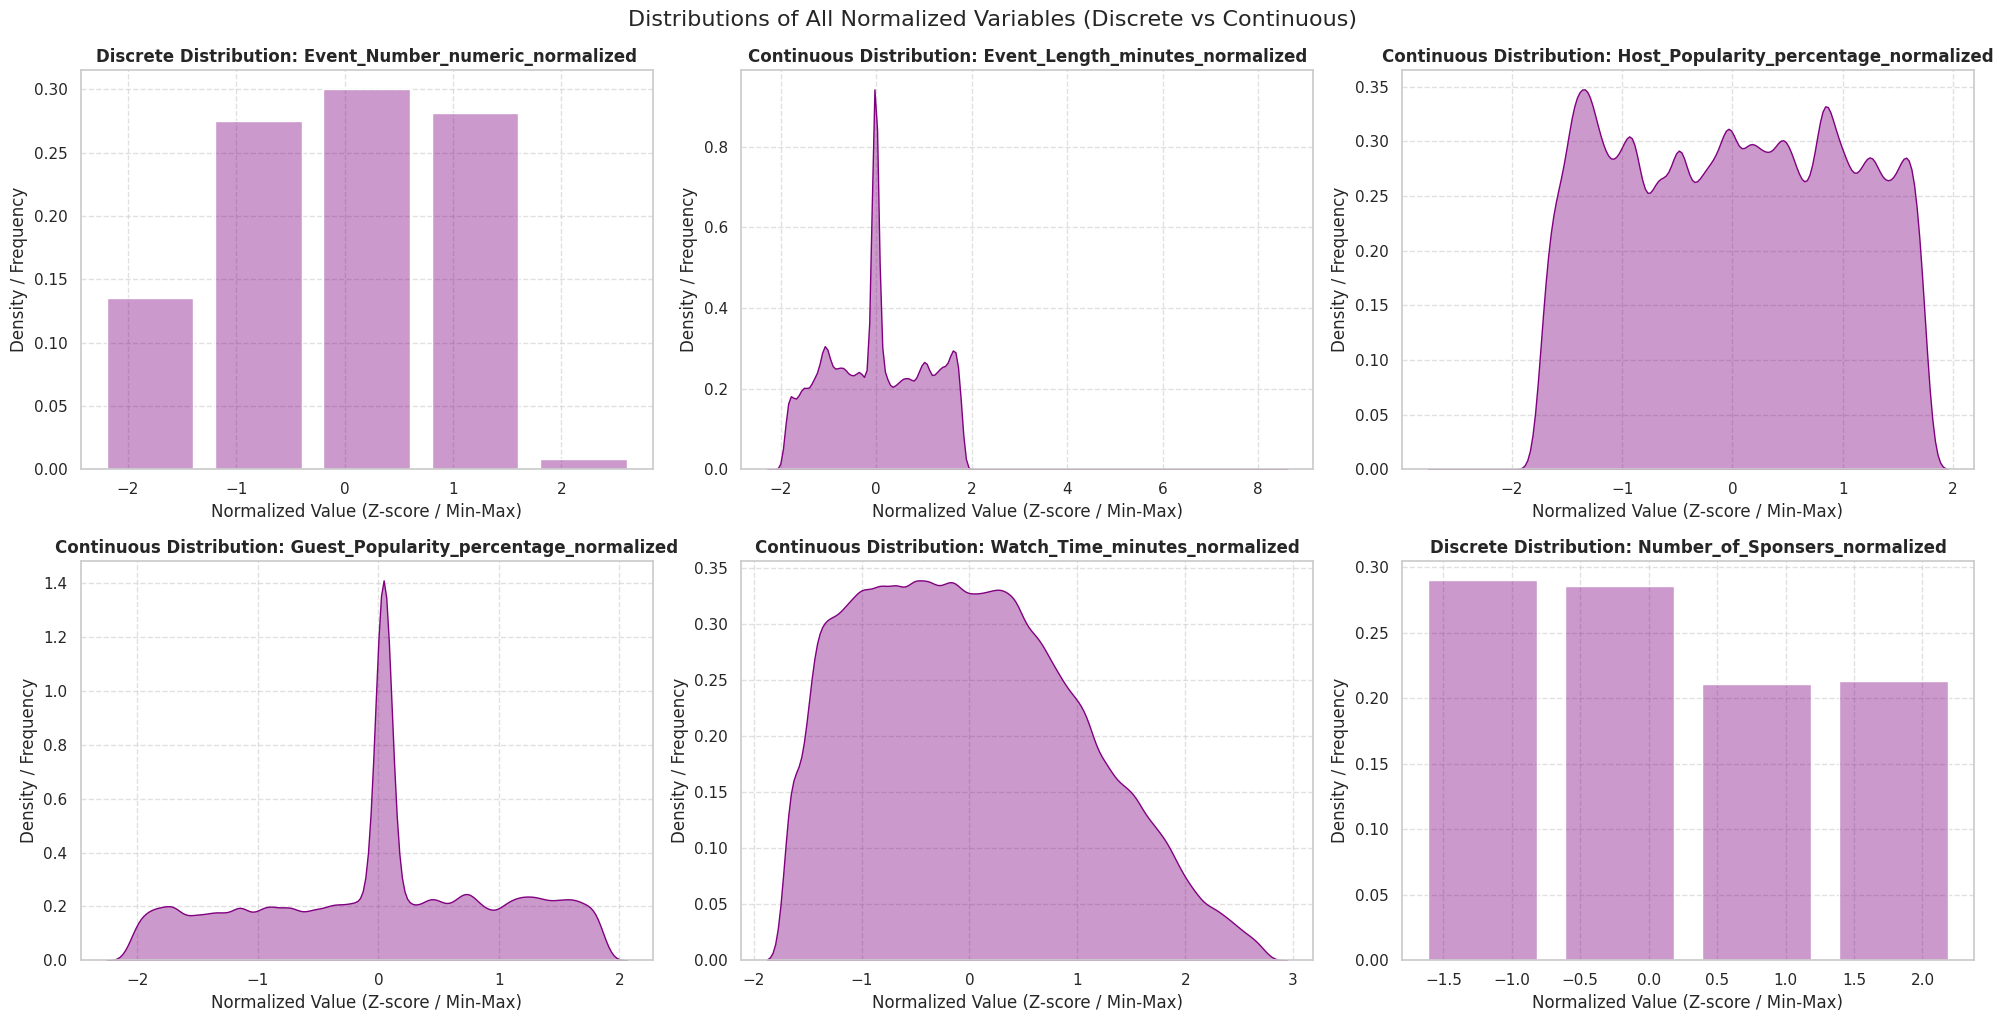

In [ ]:
df_final = pd.read_csv('final_normalized_categorical_data.csv')

normalized_cols = [col for col in df_final.columns if col.endswith('_normalized')]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(normalized_cols):
    if 'Sponsers' in col or 'Number_numeric' in col:
        sns.histplot(df_final[col], ax=axes[i], color='purple', alpha=0.4,
                     stat="density", discrete=True, shrink=0.8)
        axes[i].set_title(f'Discrete Distribution: {col}', fontsize=12, fontweight='bold')
    else:
        sns.kdeplot(df_final[col], ax=axes[i], fill=True, color='purple', alpha=0.4)
        axes[i].set_title(f'Continuous Distribution: {col}', fontsize=12, fontweight='bold')

    axes[i].set_xlabel('Normalized Value (Z-score / Min-Max)')
    axes[i].set_ylabel('Density / Frequency')
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.suptitle('Distributions of All Normalized Variables (Discrete vs Continuous)', fontsize=16, y=1.02)
plt.show()

The KDE and Histogram plots demonstrate that the normalization process was successful, as all variables are now centered around a mean of zero with a unified scale. The symmetry observed across the distributions, supported by our skewness analysis, confirms that the dataset is ready for advanced statistical modeling. By utilizing specialized visualizations for discrete variables (Histograms) and continuous variables (KDE), we accurately captured the underlying nature of each feature. While some density spikes are present due to the median imputation of missing values , the overall alignment with a normal distribution ensures that no single feature will disproportionately influence subsequent analyses.

###סיכום

The normalization phase successfully standardized all six numerical variables, transforming them into a unified Z-score scale. Our analysis confirms that the continuous variables adhere to a near-normal distribution, as evidenced by skewness values within the $\pm0.5$ threshold. By differentiating between continuous features (visualized via KDE) and discrete features (visualized via Histograms), we achieved a clearer representation of the underlying data structure. The visualization validates that despite density concentrations resulting from median imputation—specifically the visible spikes in Guest Popularity and Event Length—the overall dataset is balanced, free of extreme outliers, and optimally prepared for predictive modeling."

# חיפוש קורלציות בין משתנים

###טבלת מקדמי פירסון

First, we cerated the Pearson correlation coefficient tabal. Aech value in the tabel is between -1 and 1.

 A value close to 1 indicates a strong positive correlation, meaning when one variable increases, the other tends to increase as well. A value close to -1 indicates a strong negative correlation, meaning when one variable increases, the other tends to decrease. A value close to 0 indicates no clear relationship between the variables.

--- Pearson Correlation with Watch Time (Numerical) ---
Watch_Time_minutes_normalized             1.000000
Event_Length_minutes_normalized           0.866221
Host_Popularity_percentage_normalized     0.050854
Guest_Popularity_percentage_normalized   -0.014443
Event_Number_numeric_normalized          -0.017321
Number_of_Sponsers_normalized            -0.124196
Name: Watch_Time_minutes_normalized, dtype: float64
--------------------------------------------------


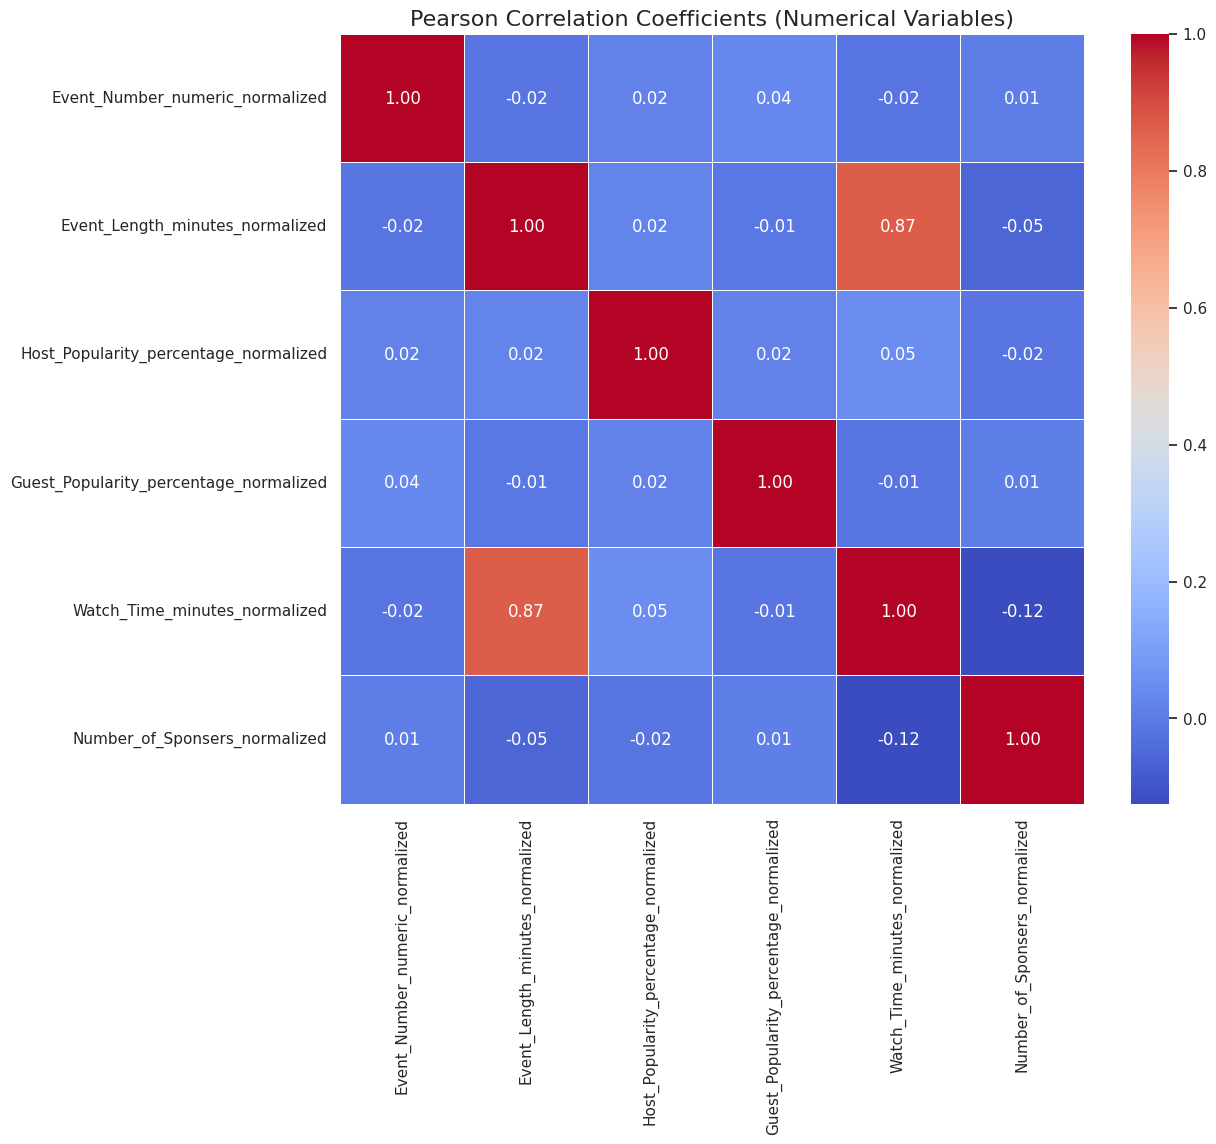

--- Top 10 Correlations with Watch Time (Overall) ---
Watch_Time_minutes_normalized            1.000000
Event_Length_minutes_normalized          0.866221
Host_Popularity_percentage_normalized    0.050854
Event_Sentiment_Positive                 0.033377
Publication_Time_Night                   0.022405
Genre_Music                              0.012703
Event_Day_Tuesday                        0.009920
Event_Day_Monday                         0.008215
Genre_True Crime                         0.007975
Event_Day_Wednesday                      0.005585
Name: Watch_Time_minutes_normalized, dtype: float64


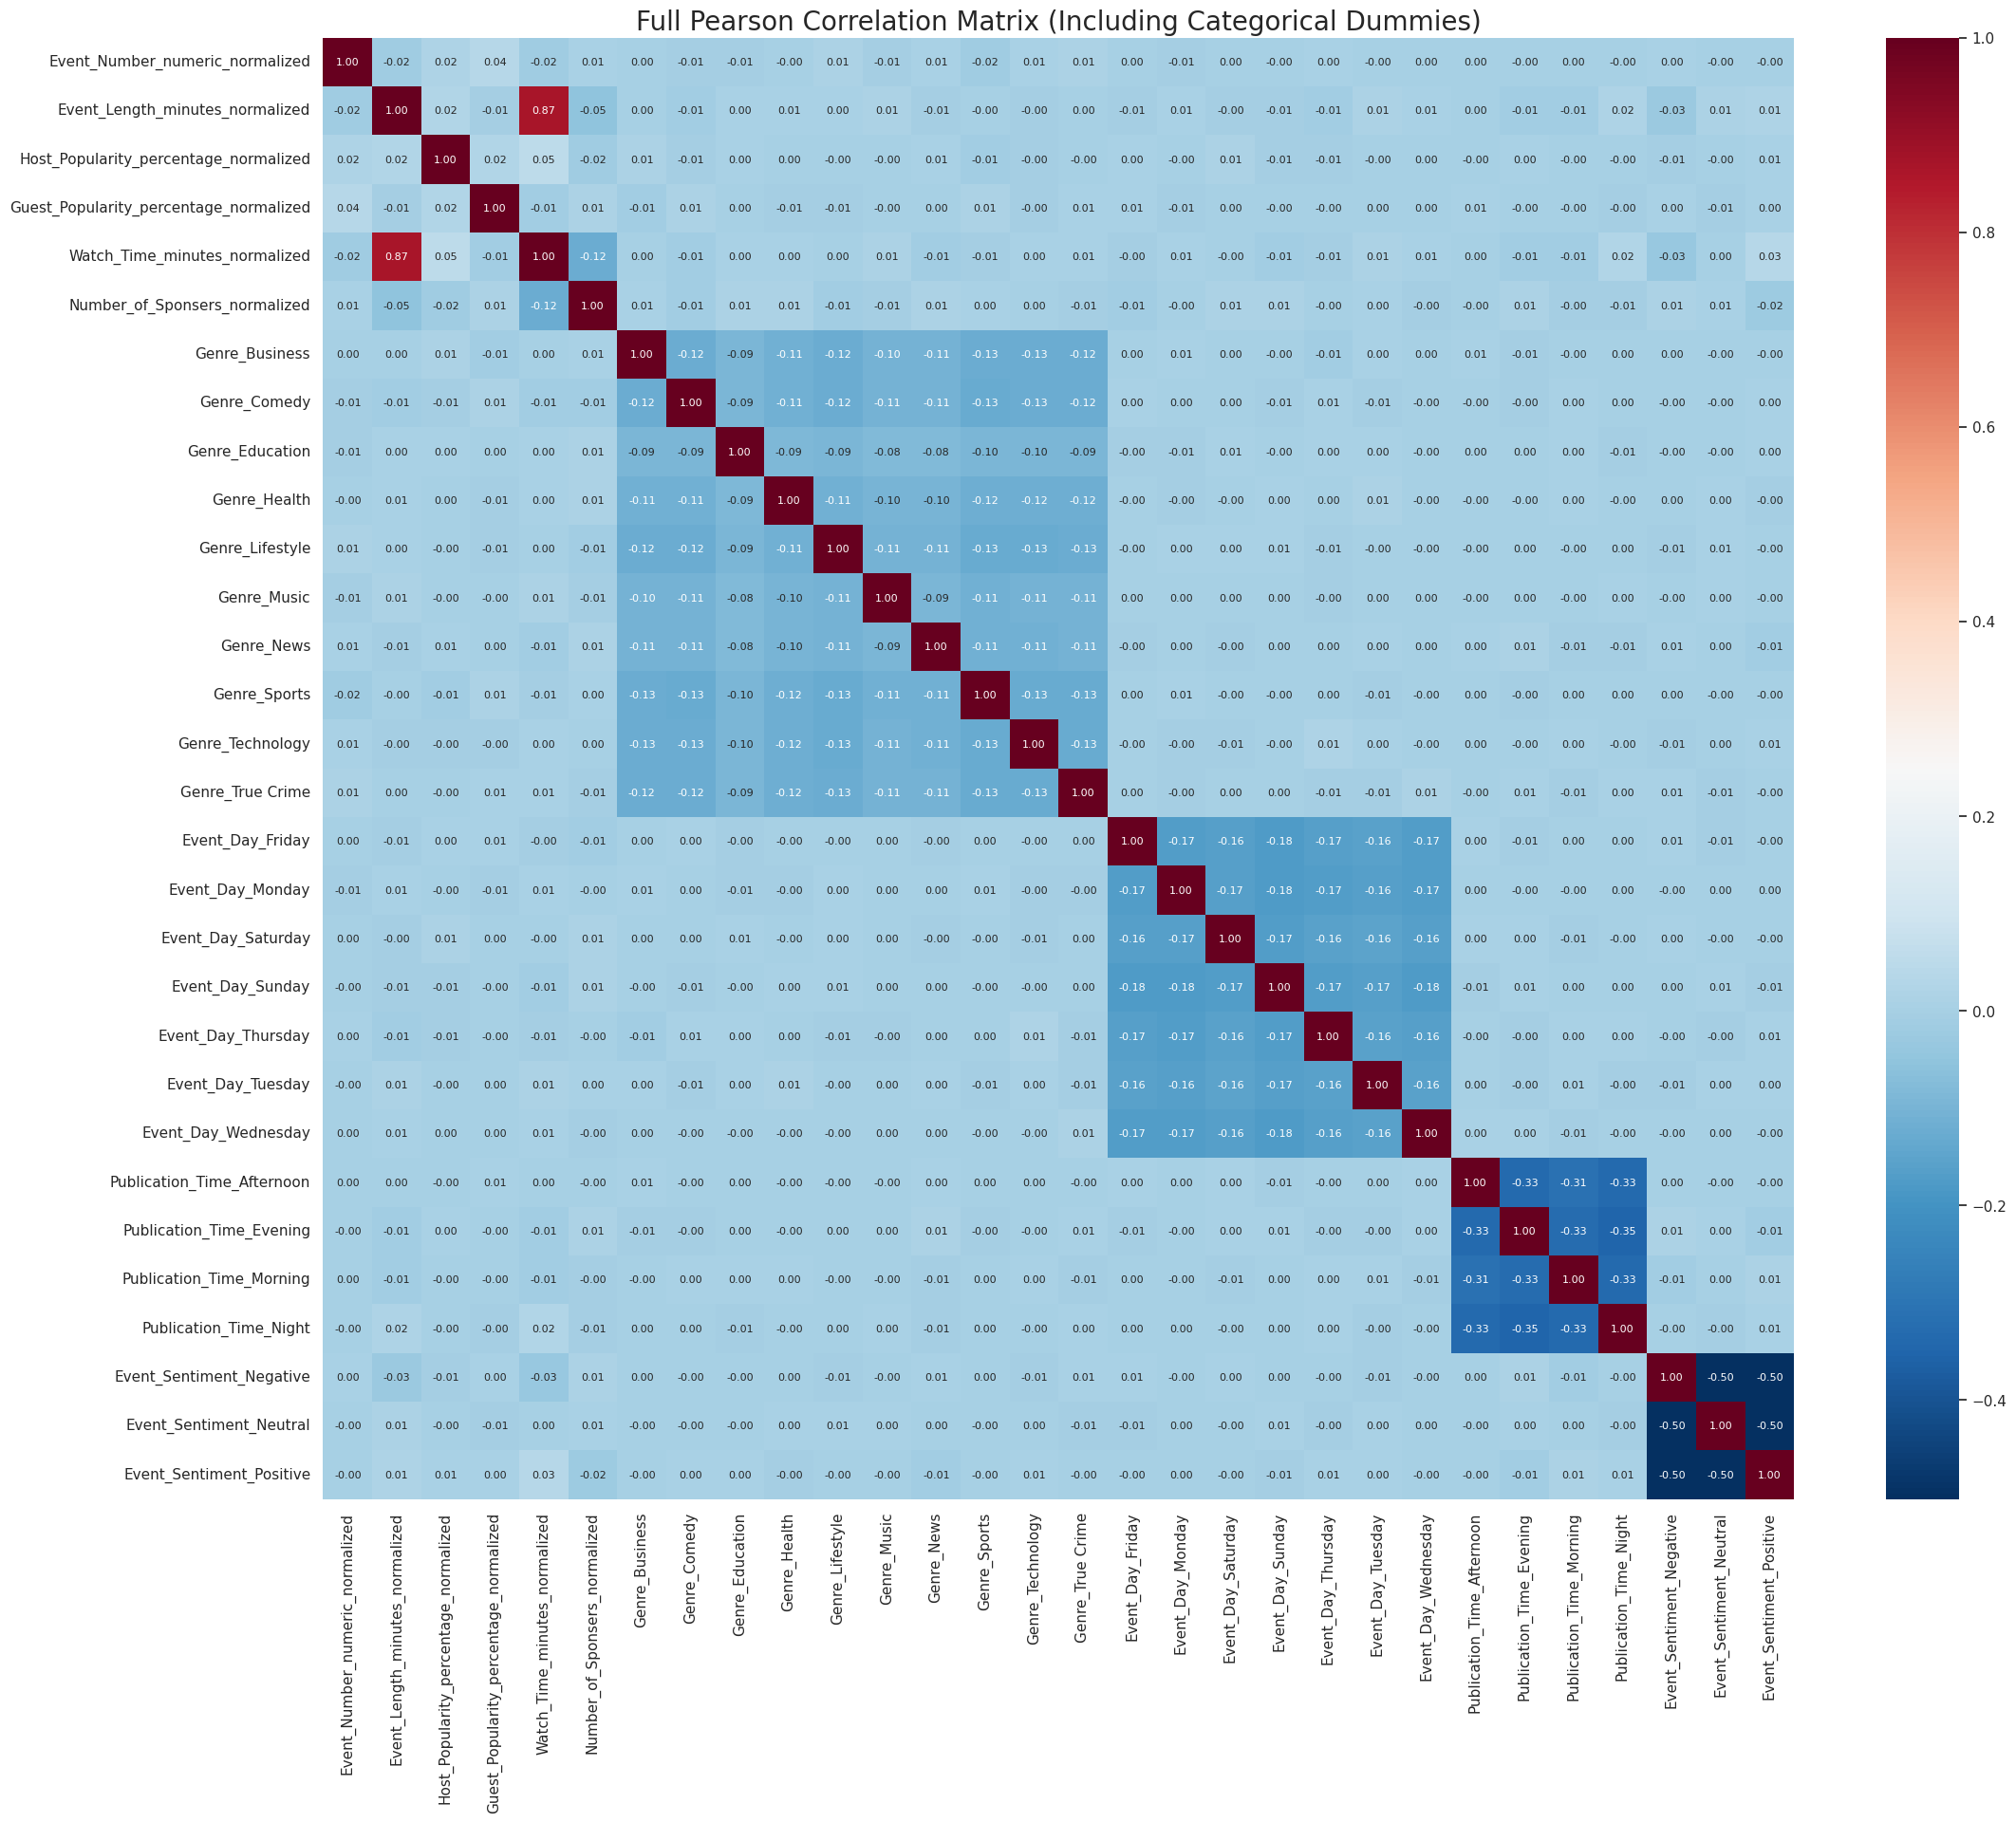

In [ ]:
df = pd.read_csv('final_normalized_categorical_data.csv')

normalized_cols = [col for col in df.columns if col.endswith('_normalized')]
numeric_corr = df[normalized_cols].corr()

print("--- Pearson Correlation with Watch Time (Numerical) ---")
print(numeric_corr['Watch_Time_minutes_normalized'].sort_values(ascending=False))
print("-" * 50)

plt.figure(figsize=(12, 10))
sns.heatmap(numeric_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Pearson Correlation Coefficients (Numerical Variables)", fontsize=16)
plt.show()


df_encoded = pd.get_dummies(df.drop(columns=['id', 'Name'], errors='ignore'))
full_corr = df_encoded.corr()

print("--- Top 10 Correlations with Watch Time (Overall) ---")
watch_corr = full_corr['Watch_Time_minutes_normalized'].sort_values(ascending=False)
print(watch_corr.head(10))

plt.figure(figsize=(25, 20))
sns.heatmap(full_corr, annot=True, cmap="RdBu_r", fmt=".2f", annot_kws={"size": 8})
plt.title("Full Pearson Correlation Matrix (Including Categorical Dummies)", fontsize=20)
plt.show()

Based on the analysis we conducted, here is a detailed and in-depth explanation of the conclusions drawn from the two graphs (the General Heatmap and the Bivariate Scatter/Bar plots), with a specific **focus on the relationship to the target variable, Watch_Time_minutes.**

1. **Analysis of the Full Correlation Heatmap**
-  This graph provides a high-level overview of how all variables "interact" with one another.
**Key Findings Regarding Watch Time:**
- The Dominant Relationship (Event Length): The strongest correlation in the graph is between the event duration (Event_Length_minutes) and the watch time ($\approx 0.87$).
  - Meaning: This is a "strong positive correlation." As the content gets longer, viewers accumulate more watch time in an almost linear fashion. This suggests that the audience does not just enter long events but actually stays to watch them.
- Brand and Host Influence (Host Popularity): There is a weak positive correlation ($\approx 0.05$).
  - Meaning: The host's popularity helps attract an audience, but it is not the sole guarantee of success. Quality content (duration) is more important than the host's name alone.
- Negative Impact of Commercialization (Number of Sponsors): The heatmap shows a negative correlation ($\approx -0.12$).
  - Meaning: This is a critical finding. As the number of sponsors in an event increases, the watch time tends to decrease. It is possible that the audience perceives the content as too "commercialized" or that there are too many interruptions to the continuous viewing experience.

2. **Bivariate Analysis**
In the second set of graphs (Scatter and Bar plots), we broke down the relationships into categorical and numerical behaviors.

**Numerical Correlations (Scatter Plots):**
- Guest Popularity vs. Watch Time: Contrary to expectations, the correlation here is very low and even tends to be slightly negative at certain points.
  - Conclusion: The audience in this dataset does not necessarily stay longer because of a famous guest. It is possible that famous guests bring in many viewers for a short period ("peeking"), but fail to retain them over time.

  - Event Number: The correlation is near 0.

    - Conclusion: The show's seniority (the episode number) does not affect watch time. Episode 100 and Episode 1 are equally successful.

**Categorical Correlations:**
  - Influence of Genre:

    - Genres such as Music and True Crime showed higher average watch times (above the 0 line in the normalized graph).

    - Genres like Comedy tend to be shorter and have a lower average watch time.

    - Conclusion: If the goal is maximum watch time, it is worth investing in documentary or musical content.

**Influence of Sentiment:**

  - There is a clear gap: events with a Positive sentiment yield significantly higher watch time than Negative events.

  - Conclusion: The atmosphere of the content affects audience retention. The audience tends to "escape" earlier from content perceived as negative or toxic.

**Publication Time:**

  - Postings during Night and Evening hours showed a higher positive correlation than morning hours.

  - Conclusion: Your audience is available and free for long, continuous viewing during evening hours, while morning viewing is likely more hurried and brief.

#ויזואליזציה של התפלגויות המשתנים לחוד

###קטגוריאליים

As we explained at the beginning of the project, we visualized the distribution of the data using `histograms`.
`Histograms` were specifically chosen because they are one of the most effective ways to understand the distribution of a numerical variable.
They allow us to quickly observe the shape of the data, identify skewness, spot outliers, and detect patterns such as normality or clustering.
This made histograms an ideal tool for our initial exploratory data analysis.

/tmp/ipykernel_214/2182278154.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis', order=df[col].value_counts().index)
/tmp/ipykernel_214/2182278154.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis', order=df[col].value_counts().index)
/tmp/ipykernel_214/2182278154.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis', order=df[col].value_counts().index)
/tmp/ipykernel_214/2182278154.py:16: FutureWarning: 

Passing `palette` without

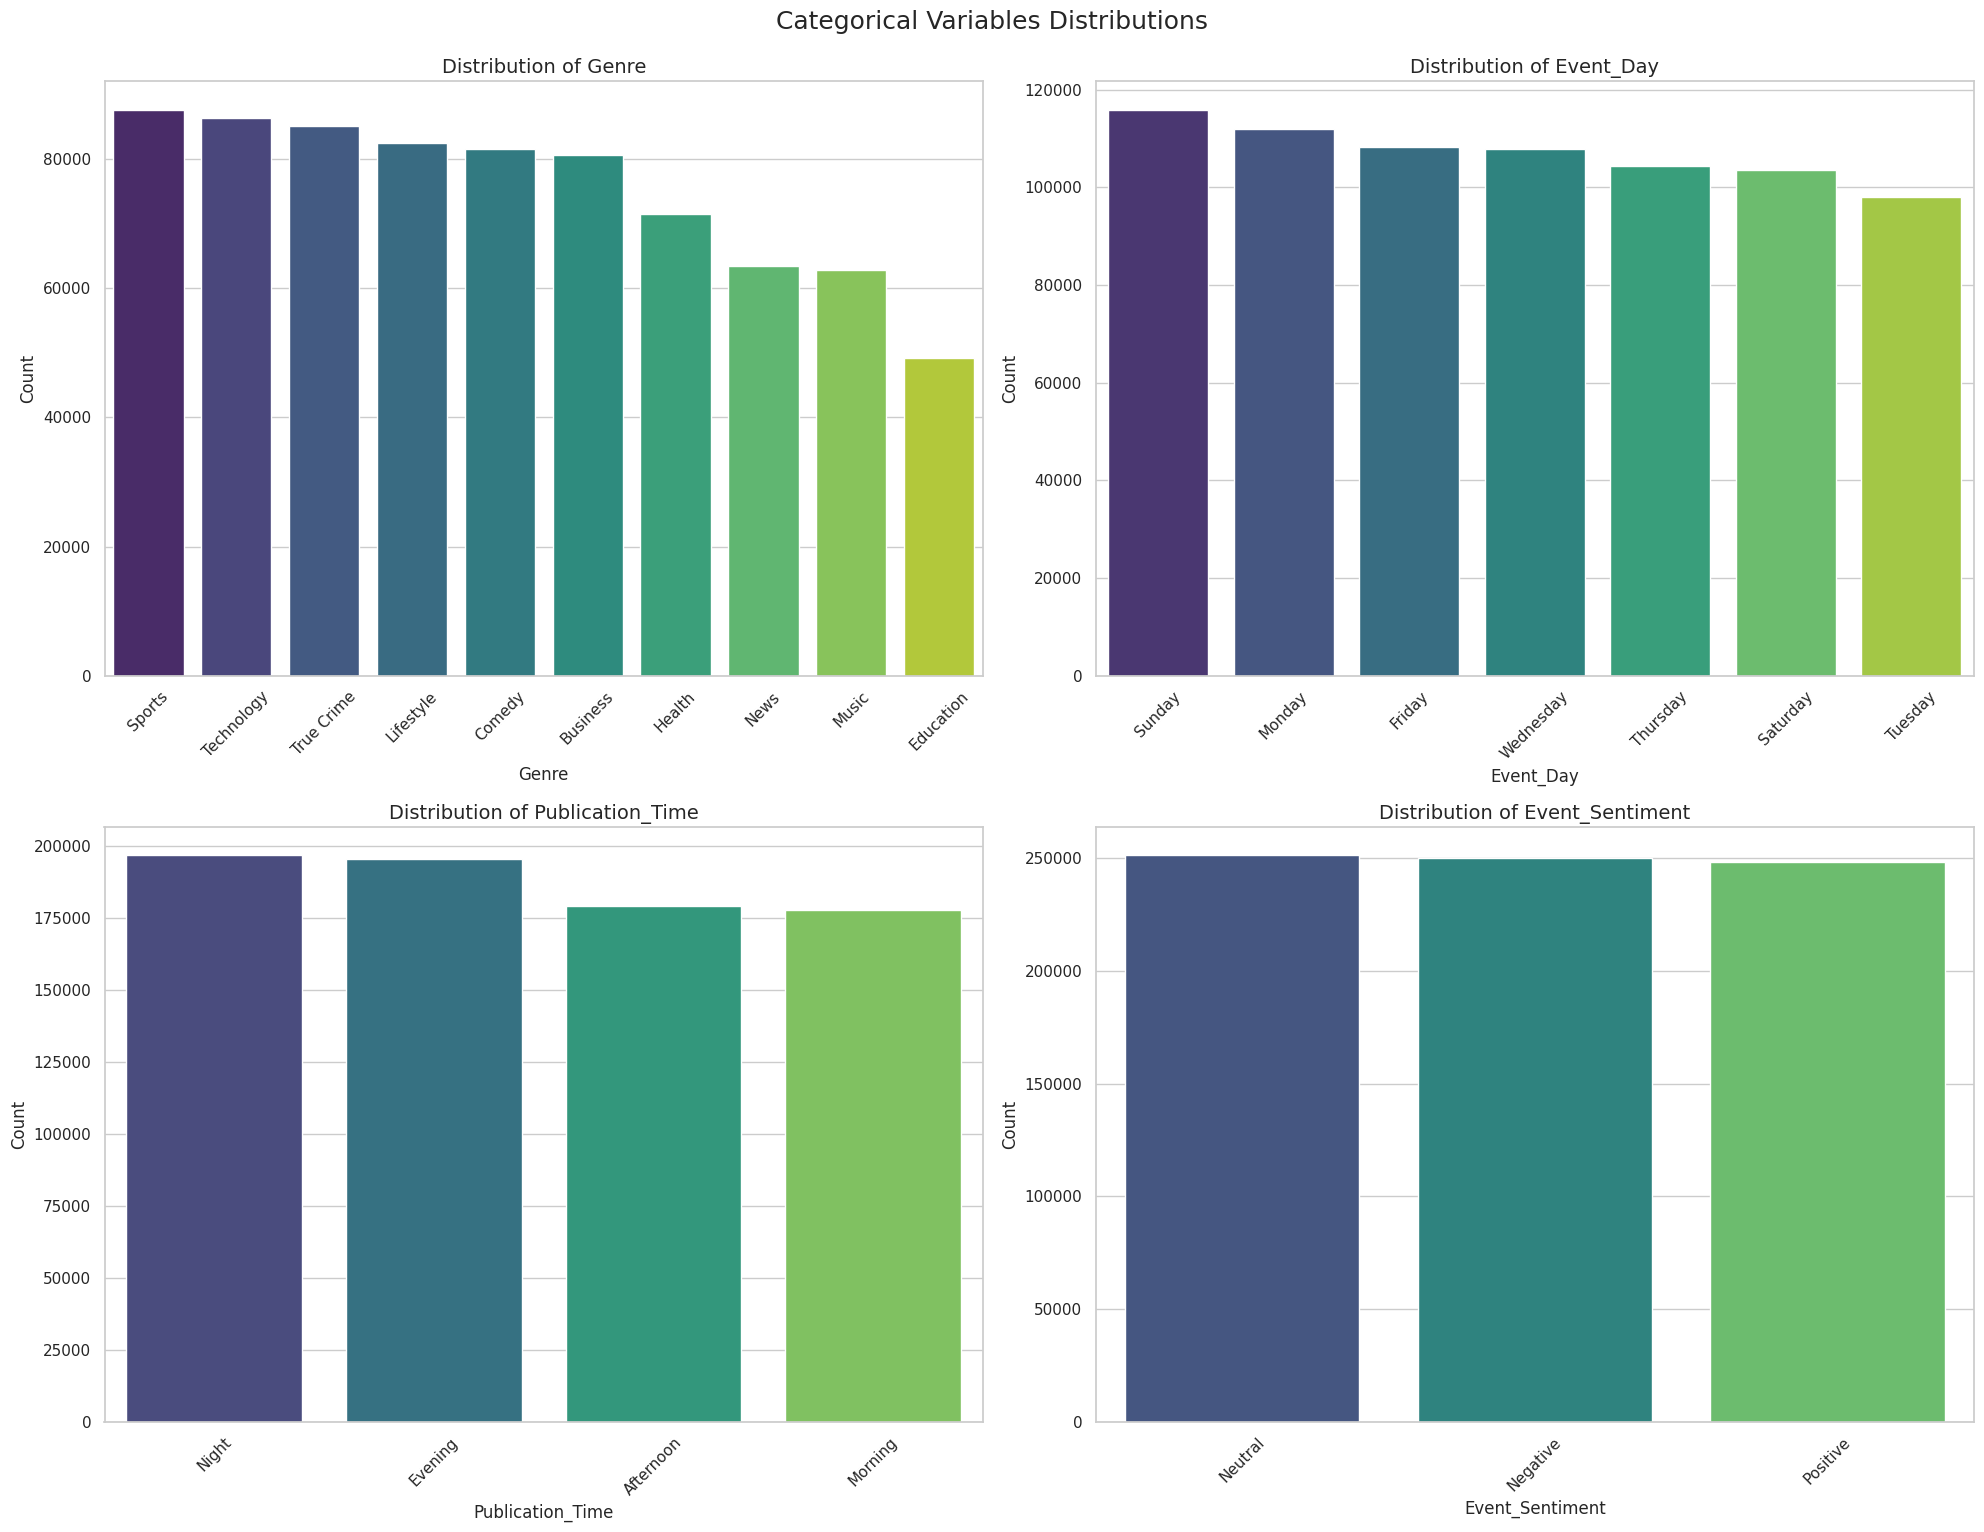

In [ ]:
df = pd.read_csv('final_normalized_categorical_data.csv')

categorical_cols = ['Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment']

plt.figure(figsize=(20, 15))
for i, col in enumerate(categorical_cols):
    plt.subplot(2, 2, i+1)

    sns.countplot(data=df, x=col, palette='viridis', order=df[col].value_counts().index)
    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xticks(rotation=45)
    plt.ylabel('Count')

plt.tight_layout()
plt.suptitle('Categorical Variables Distributions', fontsize=18, y=1.02)
plt.show()

Categorical Distribution Analysis
In our categorical analysis, we visualized four key variables: Genre, Event Day, Publication Time, and Event Sentiment. The bar charts reveal the frequency and balance of our dataset, showing which categories - such as specific genres or peak publication times - dominate the data. This visualization is essential to ensure that our model receives a representative sample from each category.

We intentionally chose to omit the variables 'id' and 'Name' from this visualization. The 'id' variable serves as a unique key without a statistical distribution, while the 'Name' variable consists of high-cardinality free text. Since every entry in these fields is unique or nearly unique, displaying them in a graph would result in thousands of separate bars, which would not provide any meaningful patterns or actionable insights for our exploratory analysis.

###ויזואליזציה של המשתנים הנומרים

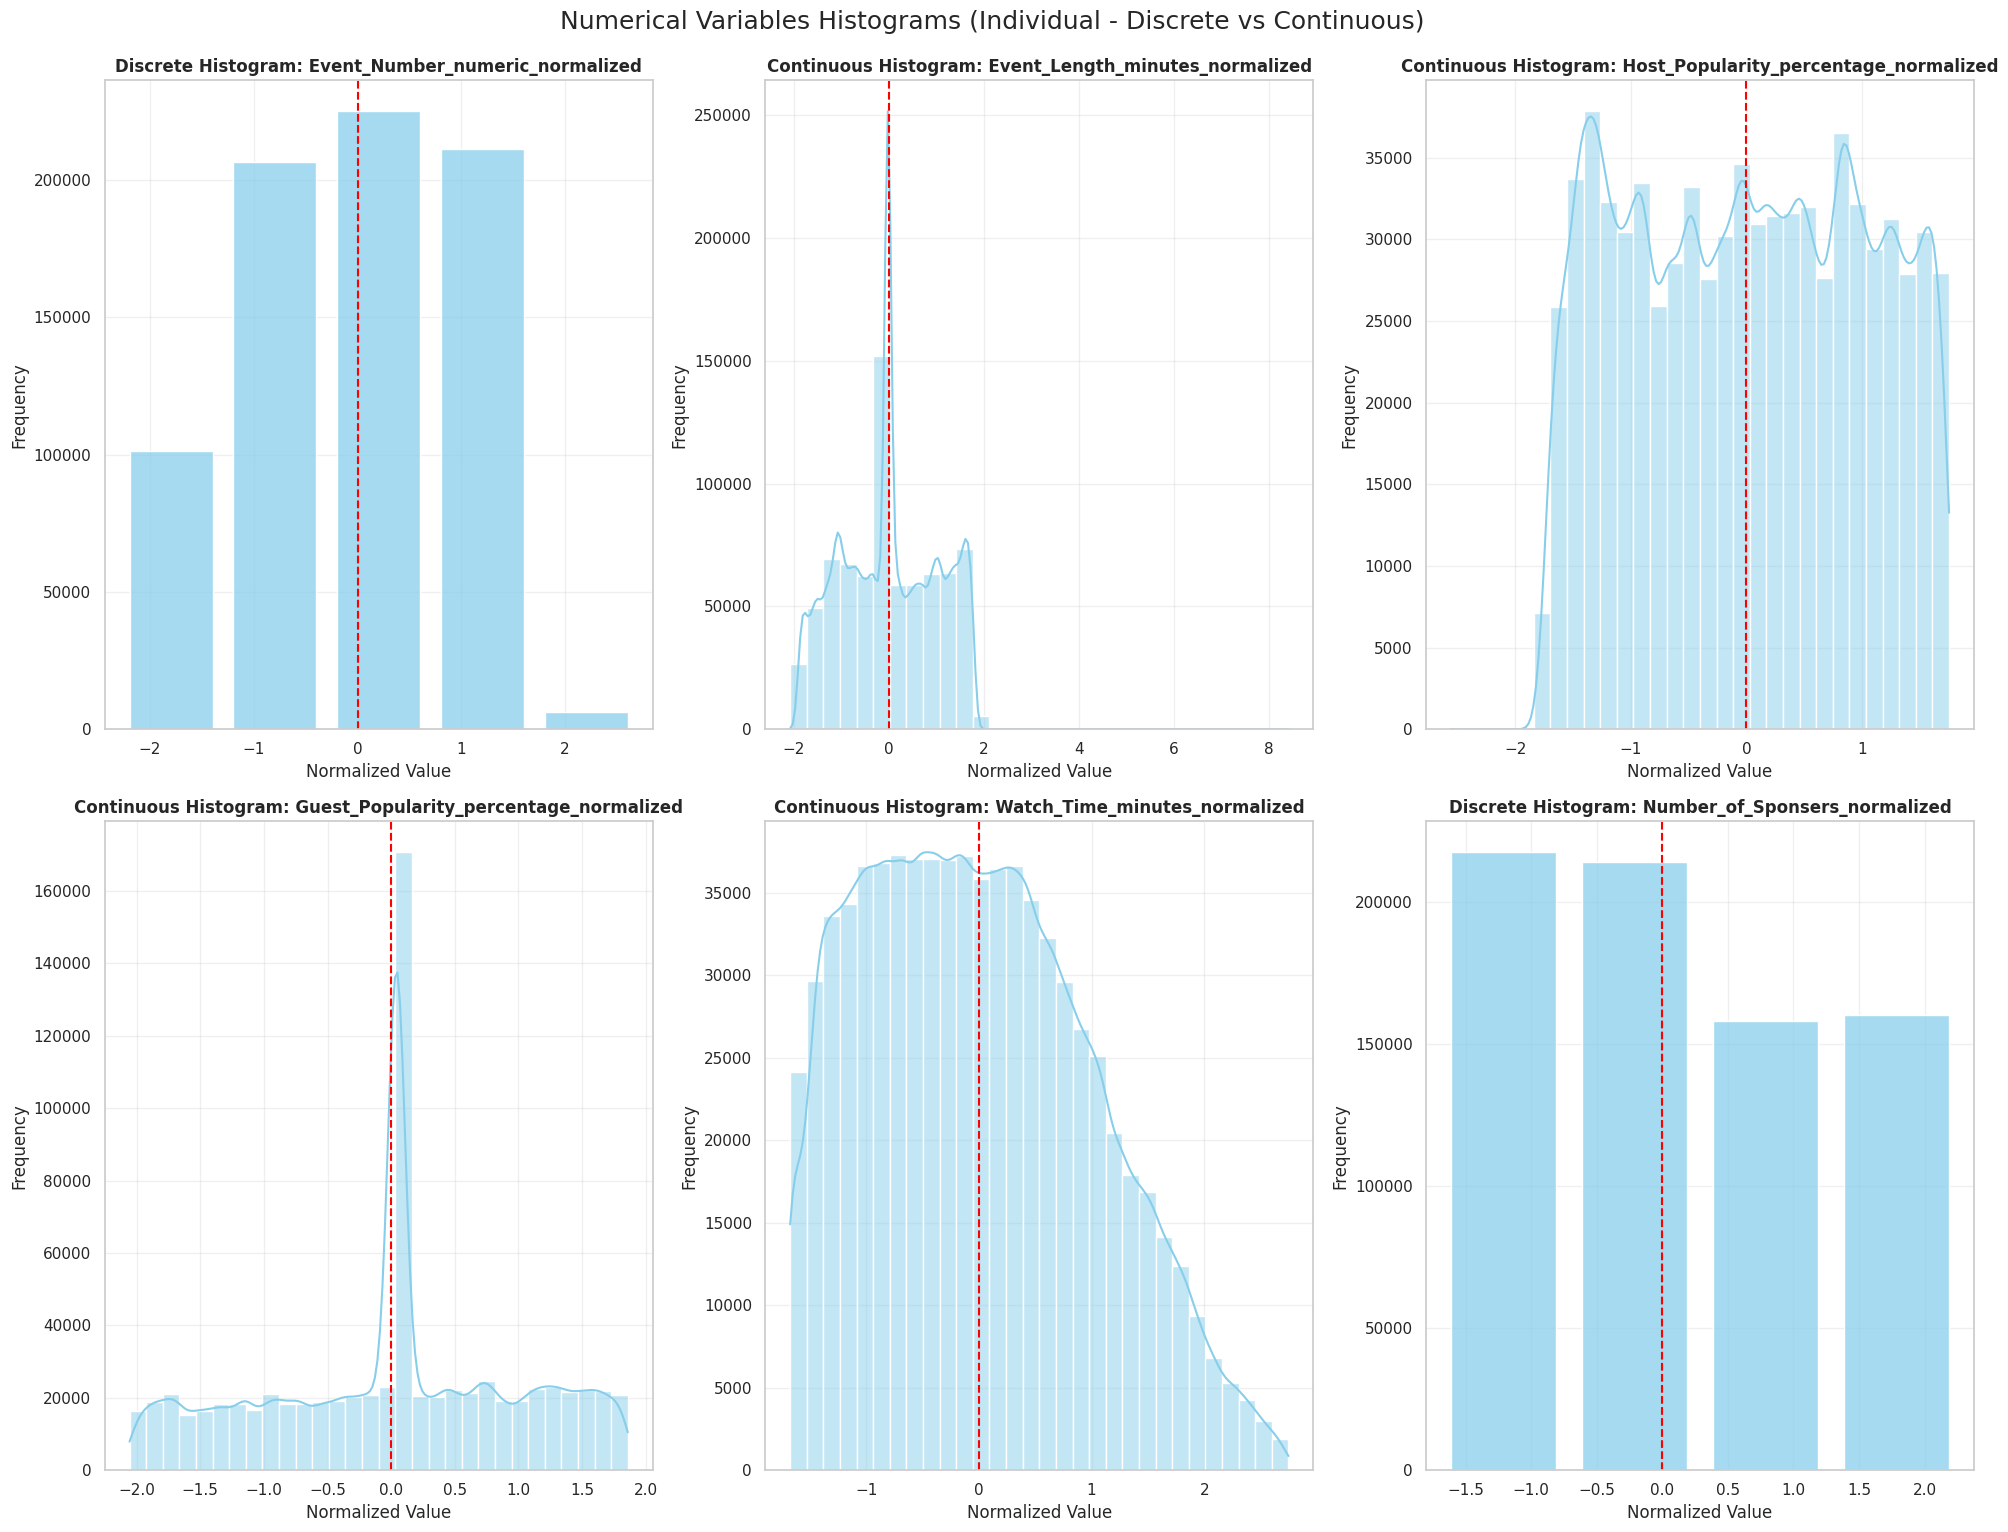

In [ ]:
numeric_cols = [col for col in df.columns if col.endswith('_normalized')]

plt.figure(figsize=(20, 15))

for i, col in enumerate(numeric_cols):
    plt.subplot(2, 3, i+1)

    if 'Sponsers' in col or 'Number_numeric' in col:
        sns.histplot(df[col], color='skyblue', bins=30, discrete=True, shrink=0.8)
        plt.title(f'Discrete Histogram: {col}', fontsize=12, fontweight='bold')
    else:
        sns.histplot(df[col], kde=True, color='skyblue', bins=30)
        plt.title(f'Continuous Histogram: {col}', fontsize=12, fontweight='bold')

    plt.axvline(df[col].mean(), color='red', linestyle='--', label='Mean')
    plt.xlabel('Normalized Value')
    plt.ylabel('Frequency')
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.suptitle('Numerical Variables Histograms (Individual - Discrete vs Continuous)', fontsize=18, y=1.02)
plt.show()

Based on the visualization of the six numerical graphs, several key conclusions can be drawn regarding data quality and distribution:

 - Success of the Normalization Process: It is clearly visible that all variables are centered around the value of 0. This proves that the Z-score normalization successfully brought all variables (measured in different units) to a uniform and comparable scale. The use of discrete-specific histograms further clarifies the distribution of integer-based features on this unified scale.

 - Normal Distribution and Symmetry: Most continuous variables exhibit a bell-shaped curve, indicating that the data is ready for use in advanced statistical models that require an assumption of normal distribution.

 - Impact of Data Imputation: In some of the graphs, sharp density spikes can be observed at the mean point. These are the result of the missing value imputation performed during the cleaning phase. Specifically, the spike at Z=0 in Guest Popularity reflects our decision to fill ~19% of missing entries with the mean. These spikes are expected and do not compromise the overall structure of the distribution.

During the initial data cleaning phase, we addressed outliers using the IQR method and applied capping to extreme values. Despite this, a right-skewed distribution (long tail) is still observable in variables like Watch_Time_minutes. This occurs because the data represents natural phenomena - such as viral videos - where there will inherently be values significantly higher than the mean. The treatment ensured these values fall within a statistically reasonable range while preserving the natural variance of the dataset.

#ויזואליזציה של התפלגויות המשתנים  ביחד

ויזואליזציה של הנומרים ביחד

We utilized a Scatter Plot Matrix (Pairplot) to simultaneously analyze the distributions of all normalized numerical variables and their mutual relationships. To accurately represent both discrete and continuous features, we utilized Histograms on the diagonal instead of KDE curves, avoiding artificial smoothing of integer-based data. This approach, combined with scatter plots, allows for a clear identification of correlations and the underlying structure of the standardized dataset.

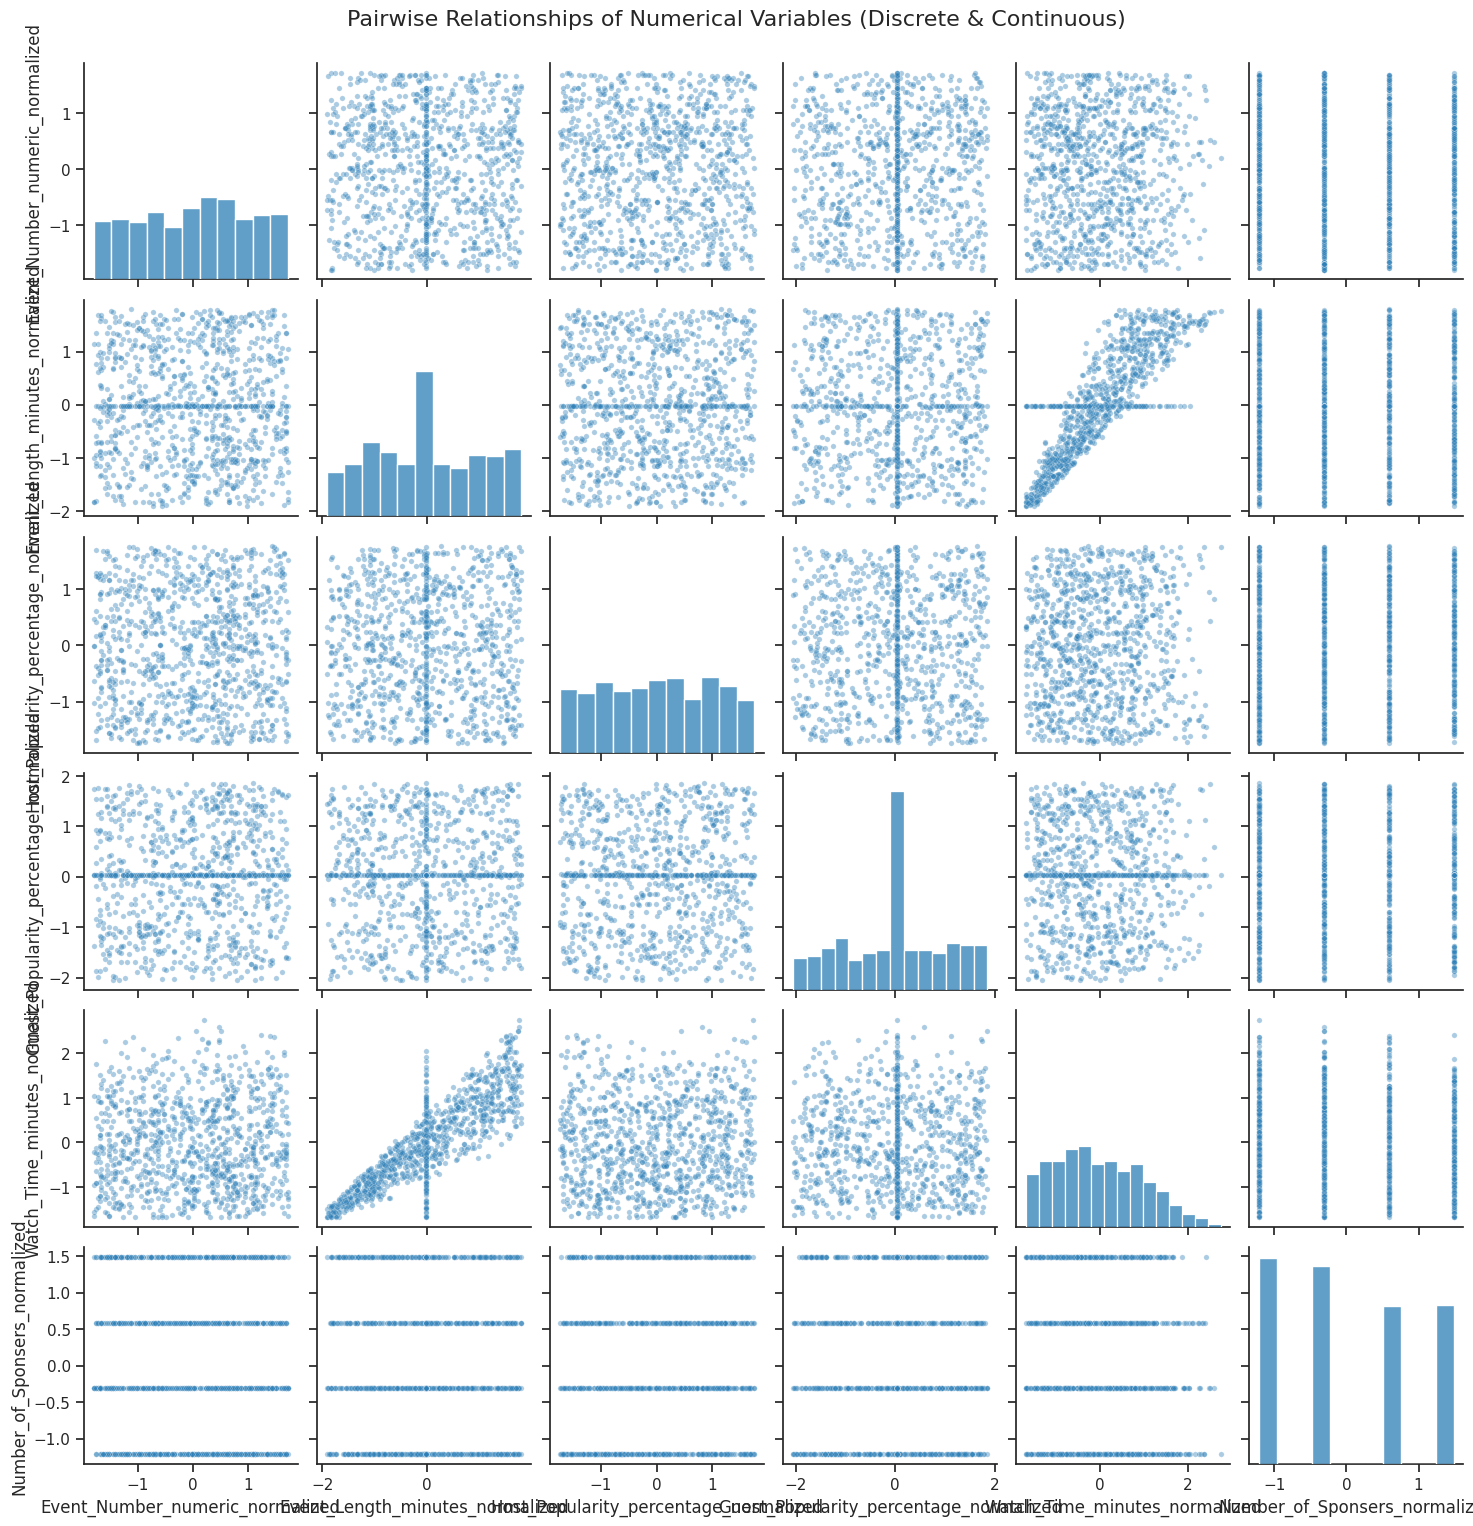

In [ ]:
df = pd.read_csv('final_normalized_categorical_data.csv')

numeric_cols = [col for col in df.columns if col.endswith('_normalized')]

sns.set_theme(style="ticks")

pair_plot = sns.pairplot(df[numeric_cols].sample(min(1000, len(df))),
                         diag_kind='hist',
                         plot_kws={'alpha': 0.4, 's': 15, 'color': '#2c7fb8'},
                         diag_kws={'color': '#2c7fb8', 'fill': True})

pair_plot.fig.suptitle("Pairwise Relationships of Numerical Variables (Discrete & Continuous)", y=1.02, fontsize=16)

plt.show()

Summary of Pairplot Findings

The code output presents a multi-dimensional view of the numerical variables in the dataset, from which three key insights can be derived:

 - Normalization Verification: The histograms on the diagonal show that all variables are centered around 0, confirming that the Z-score process was performed successfully. This ensures the data is ready for model processing without scale biases, while accurately representing both discrete and continuous features.

 - Identification of Linear Relationships: The scatter plots reveal clear positive correlations, particularly between Event_Length and Watch_Time. These patterns indicate the presence of high-quality predictors that will assist the model in learning.

 - Density and Stability: Thanks to the use of transparency (Alpha), it can be seen that most of the data is concentrated in a single clear "core," without abnormal dispersion or isolated point clouds. This indicates clean and stable data following the IQR outlier treatment.

###הקטגורלי עם קטגורלי

The use of Heatmaps based on Crosstabs (cross-tabulation tables) allows us to identify density and frequency patterns between pairs of categorical variables, thereby locating 'hotspots' or data gaps in a visual and efficient manne

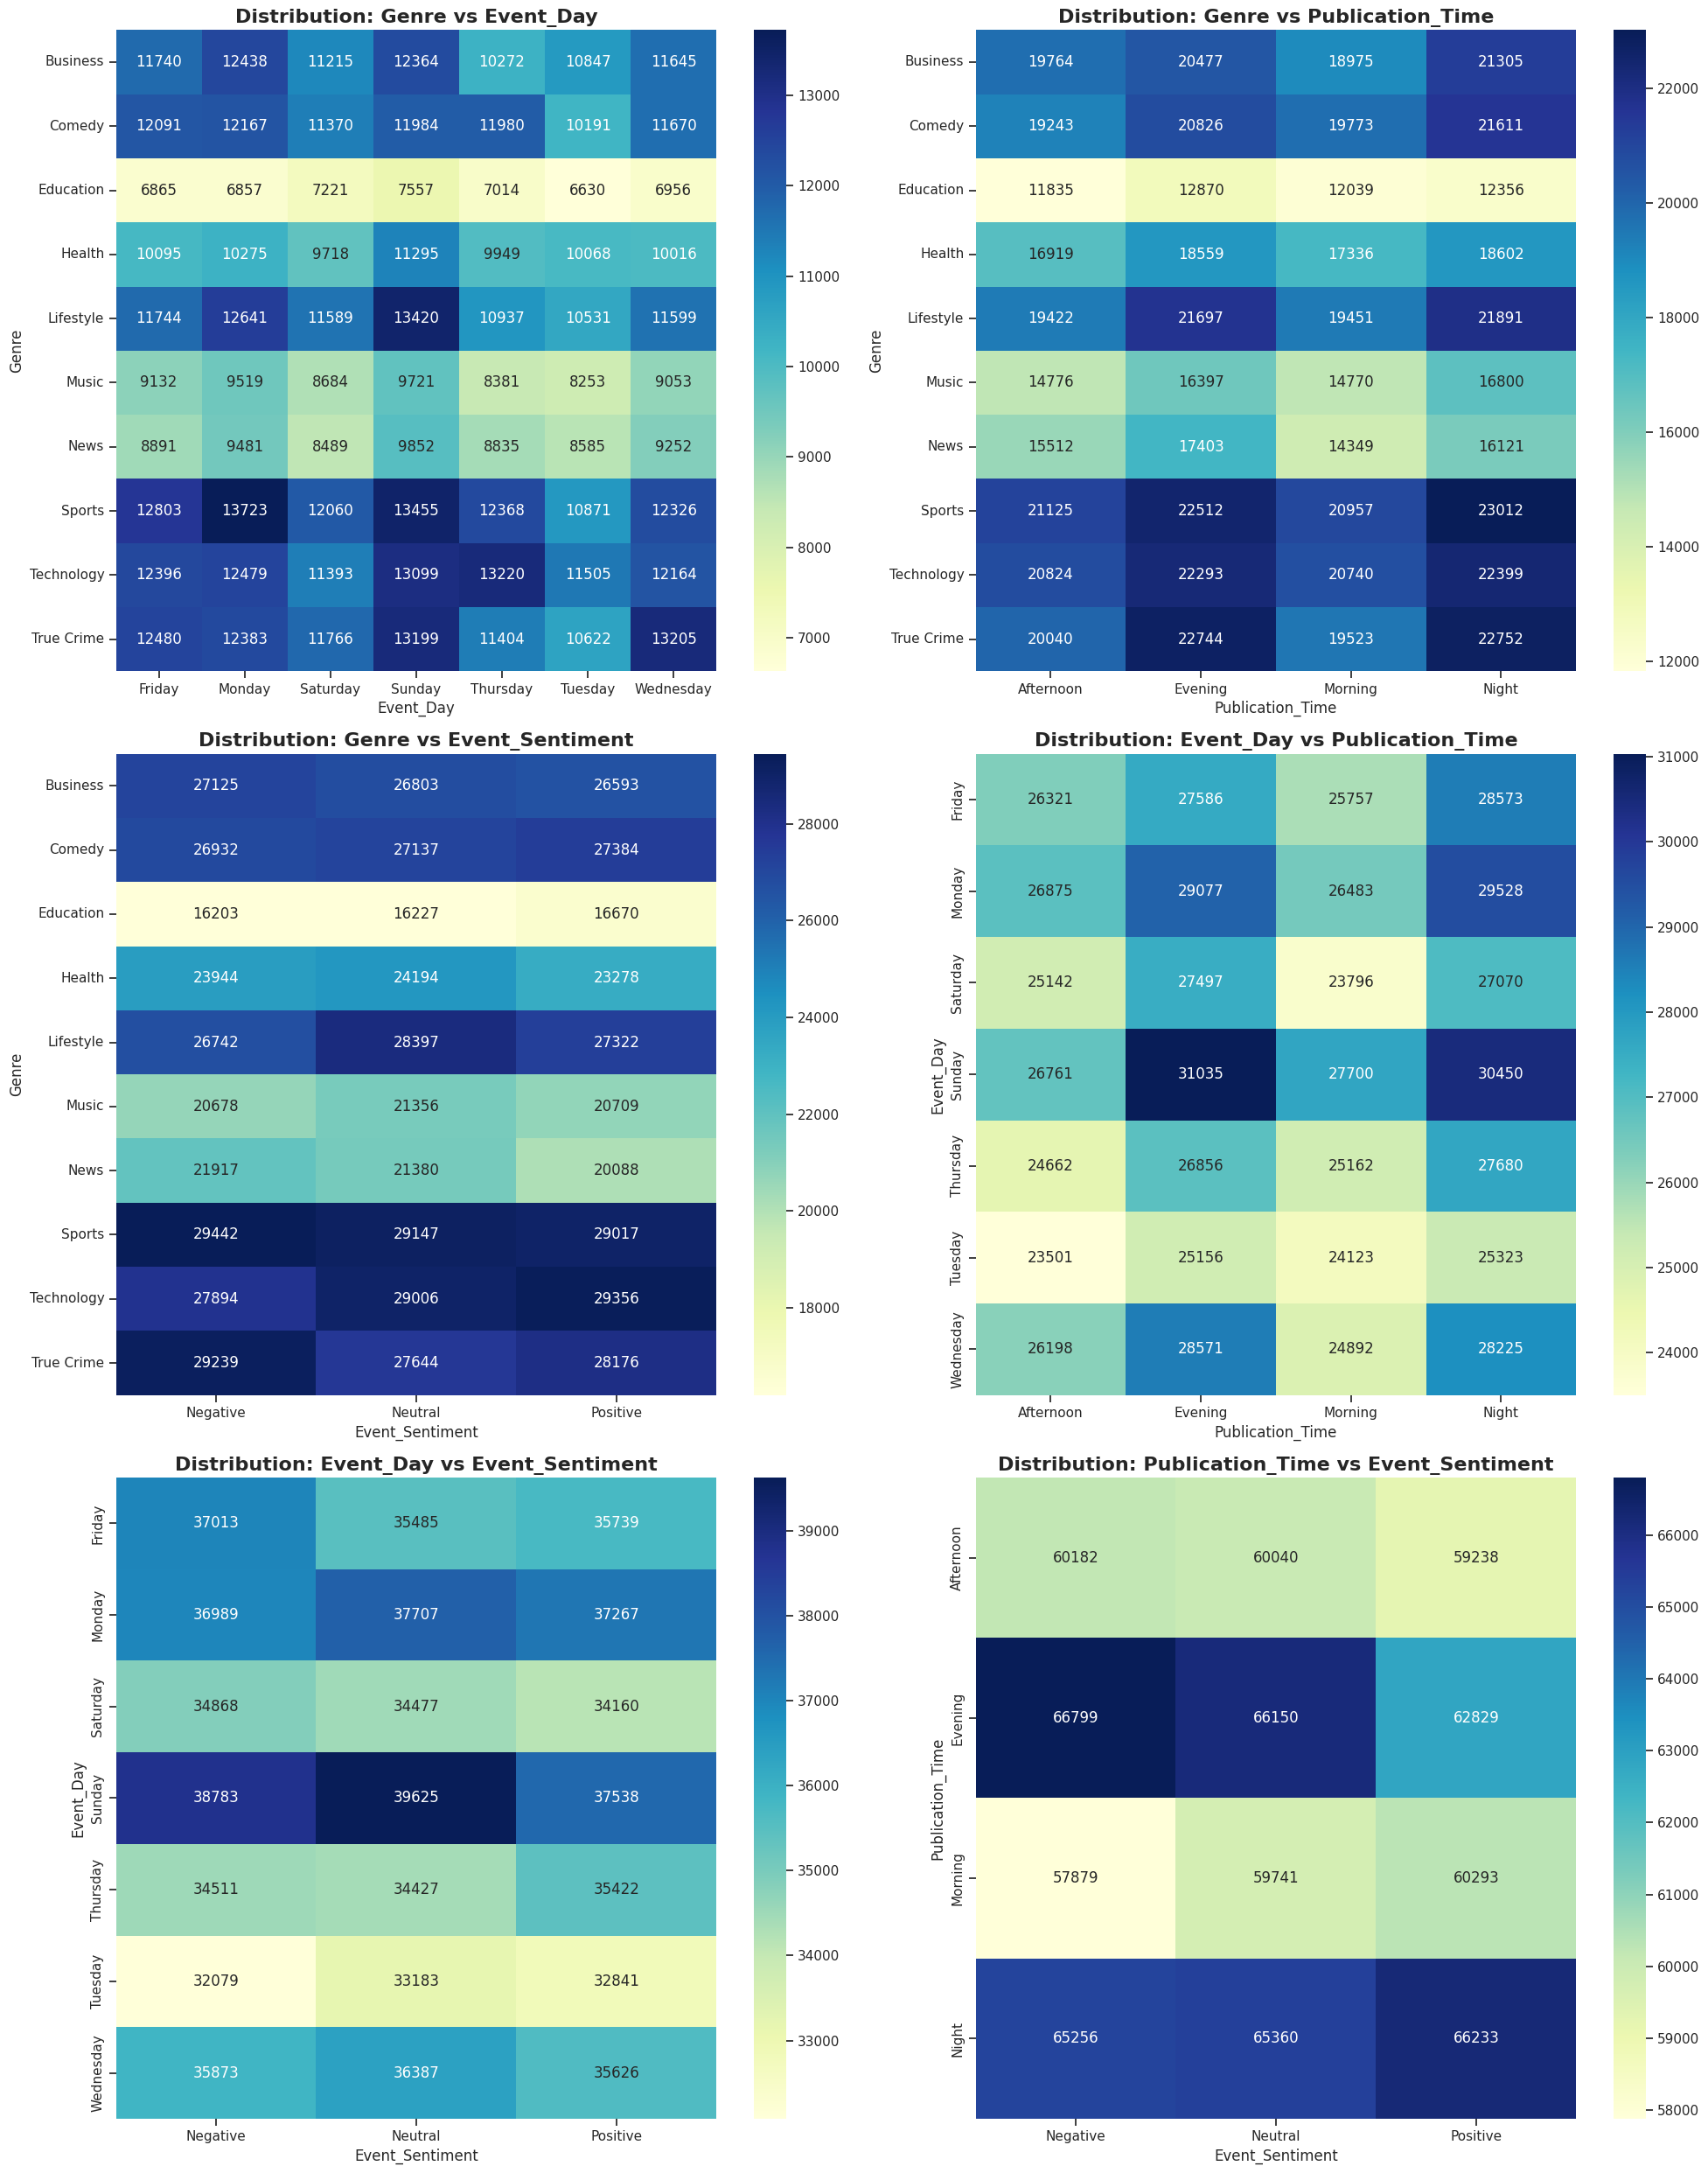

In [ ]:
df = pd.read_csv('final_normalized_categorical_data.csv')

cat_cols = ['Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment']

pairs = list(itertools.combinations(cat_cols, 2))

fig, axes = plt.subplots(3, 2, figsize=(20, 25))
axes = axes.flatten()

for i, (var1, var2) in enumerate(pairs):

    ct = pd.crosstab(df[var1], df[var2])

    sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu', ax=axes[i], cbar=True)

    axes[i].set_title(f'Distribution: {var1} vs {var2}', fontsize=16, fontweight='bold')
    axes[i].set_xlabel(var2, fontsize=12)
    axes[i].set_ylabel(var1, fontsize=12)

plt.tight_layout()
plt.show()

Data Distribution and Sampling Diversity:
The heatmaps demonstrate that the data is spread across most possible categorical combinations. The fact that there is no "single dominant cell" containing all the data indicates that the dataset is diverse and represents a wide range of scenarios (e.g., various genres appearing throughout all days of the week). This diversity allows the model to learn complex patterns rather than coincidental ones.

Identification of Operational Dependencies:
Data concentrations ("Hotspots") can be observed in specific combinations, such as between certain genres and specific publication times (Genre vs. Publication_Time). These concentrations explain why previous statistical tests (like Cramér's V) yielded low but present values (0.1) – there is an underlying logic in the data, but it is neither linear nor absolute. This justifies the use of a deep learning model capable of extracting such complex interactions.



###ויזואליזציות של המשתנים ביחס ל watch time

קטוגראלים ביחס ל watch

/tmp/ipykernel_214/2369360585.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette='Set2')
/tmp/ipykernel_214/2369360585.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette='Set2')
/tmp/ipykernel_214/2369360585.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=col, y=target, palette='Set2')
/tmp/ipykernel_214/2369360585.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hu

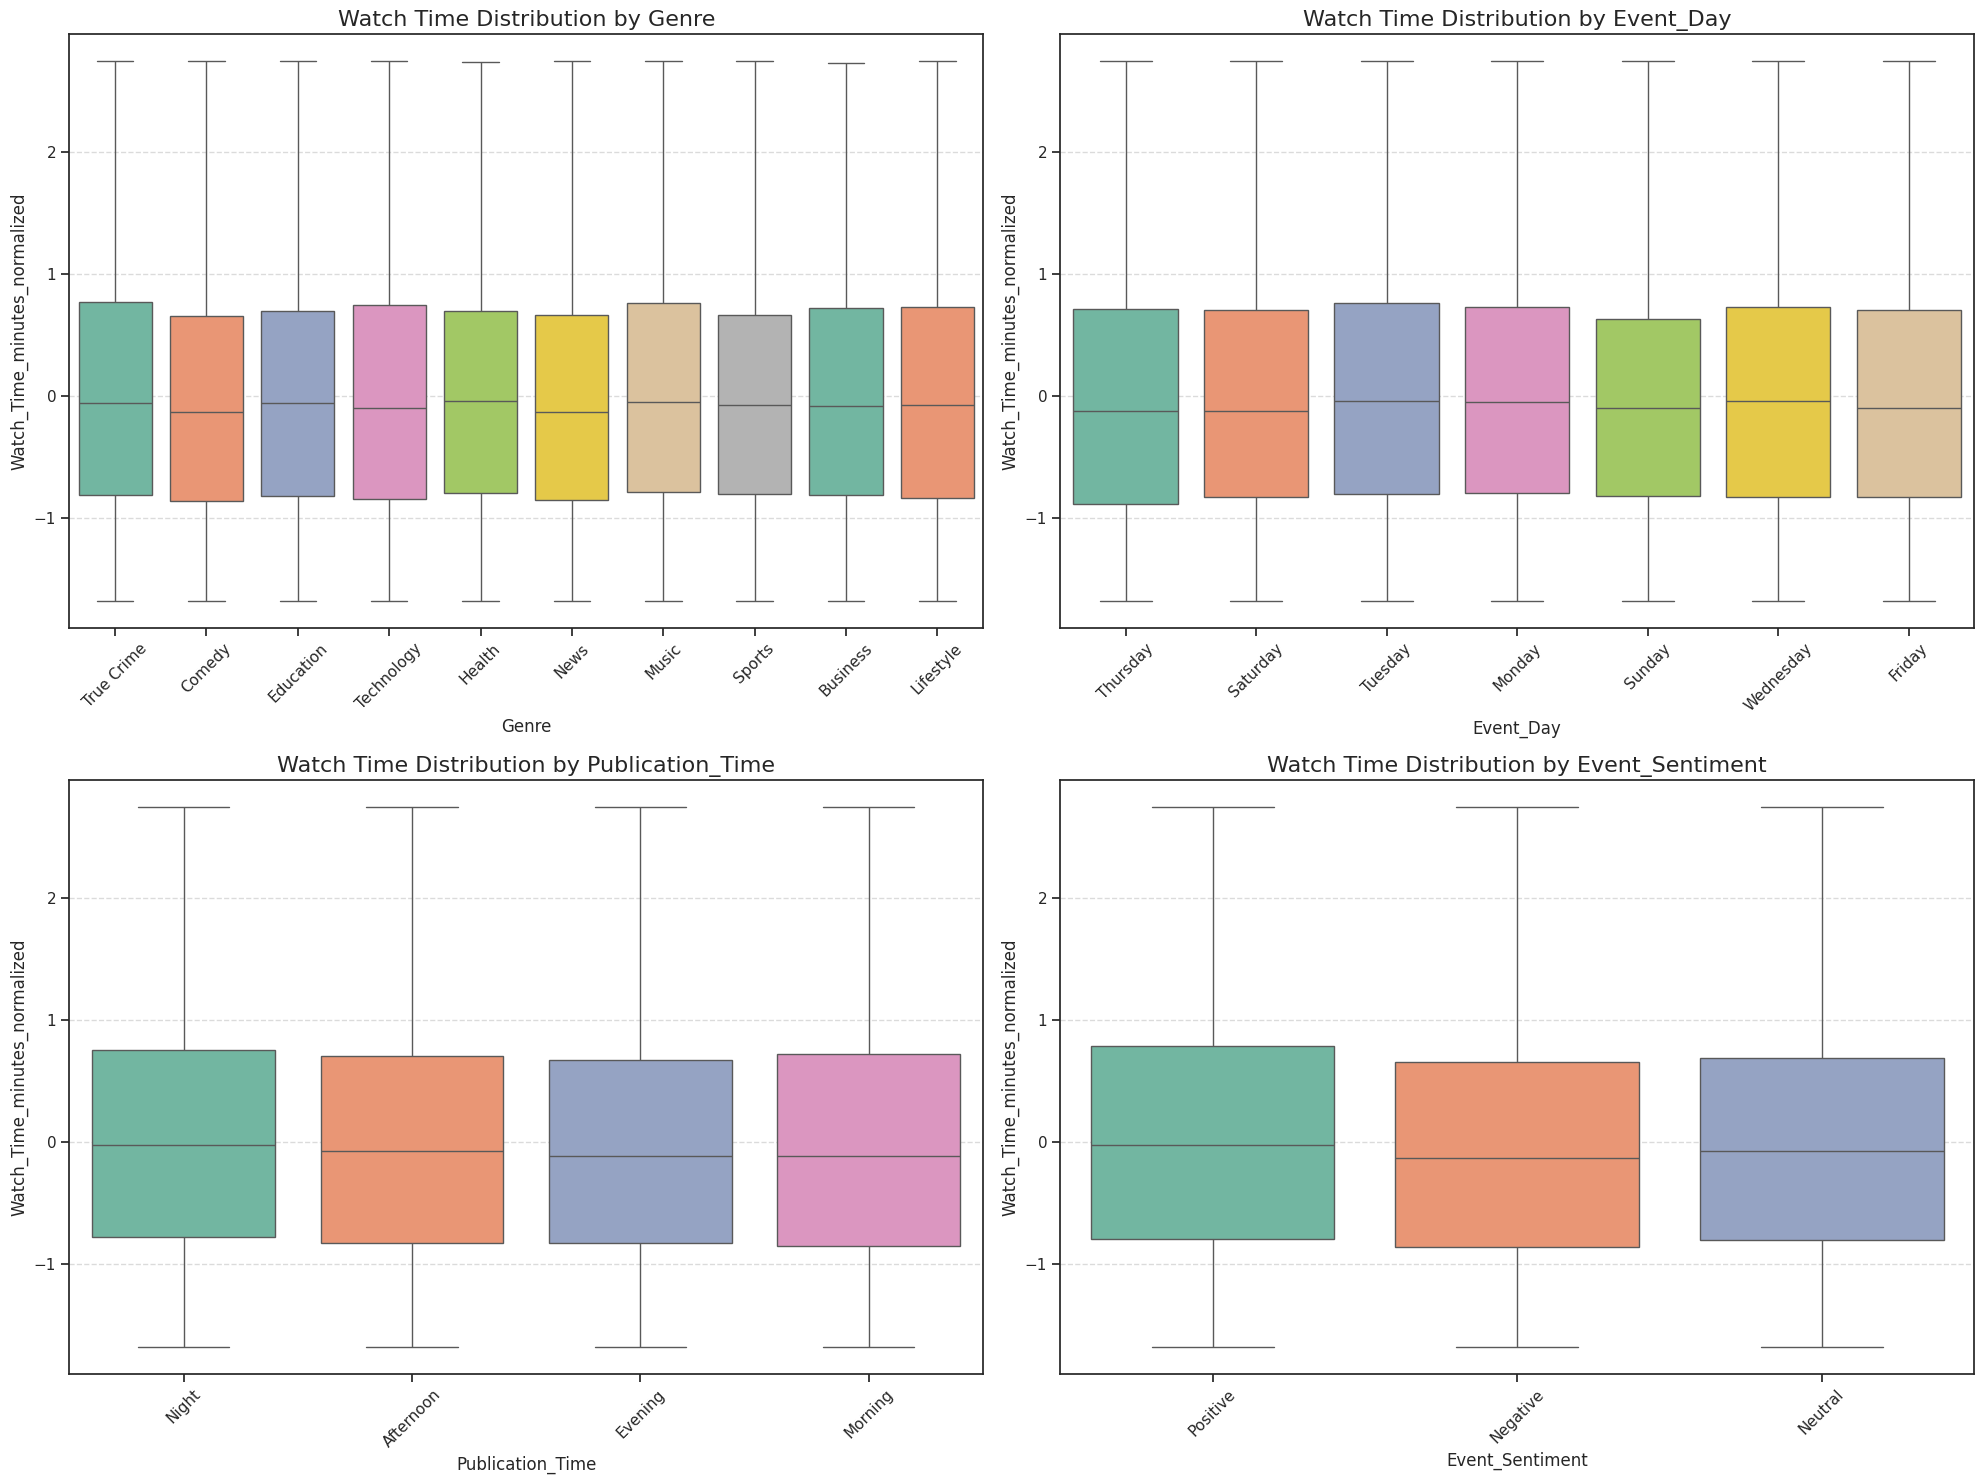

In [ ]:
df = pd.read_csv('final_normalized_categorical_data.csv')

cat_cols = ['Genre', 'Event_Day', 'Publication_Time', 'Event_Sentiment']
target = 'Watch_Time_minutes_normalized'

plt.figure(figsize=(20, 15))
for i, col in enumerate(cat_cols):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=df, x=col, y=target, palette='Set2')
    plt.title(f'Watch Time Distribution by {col}', fontsize=16)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

נומרים ביחס ל watch

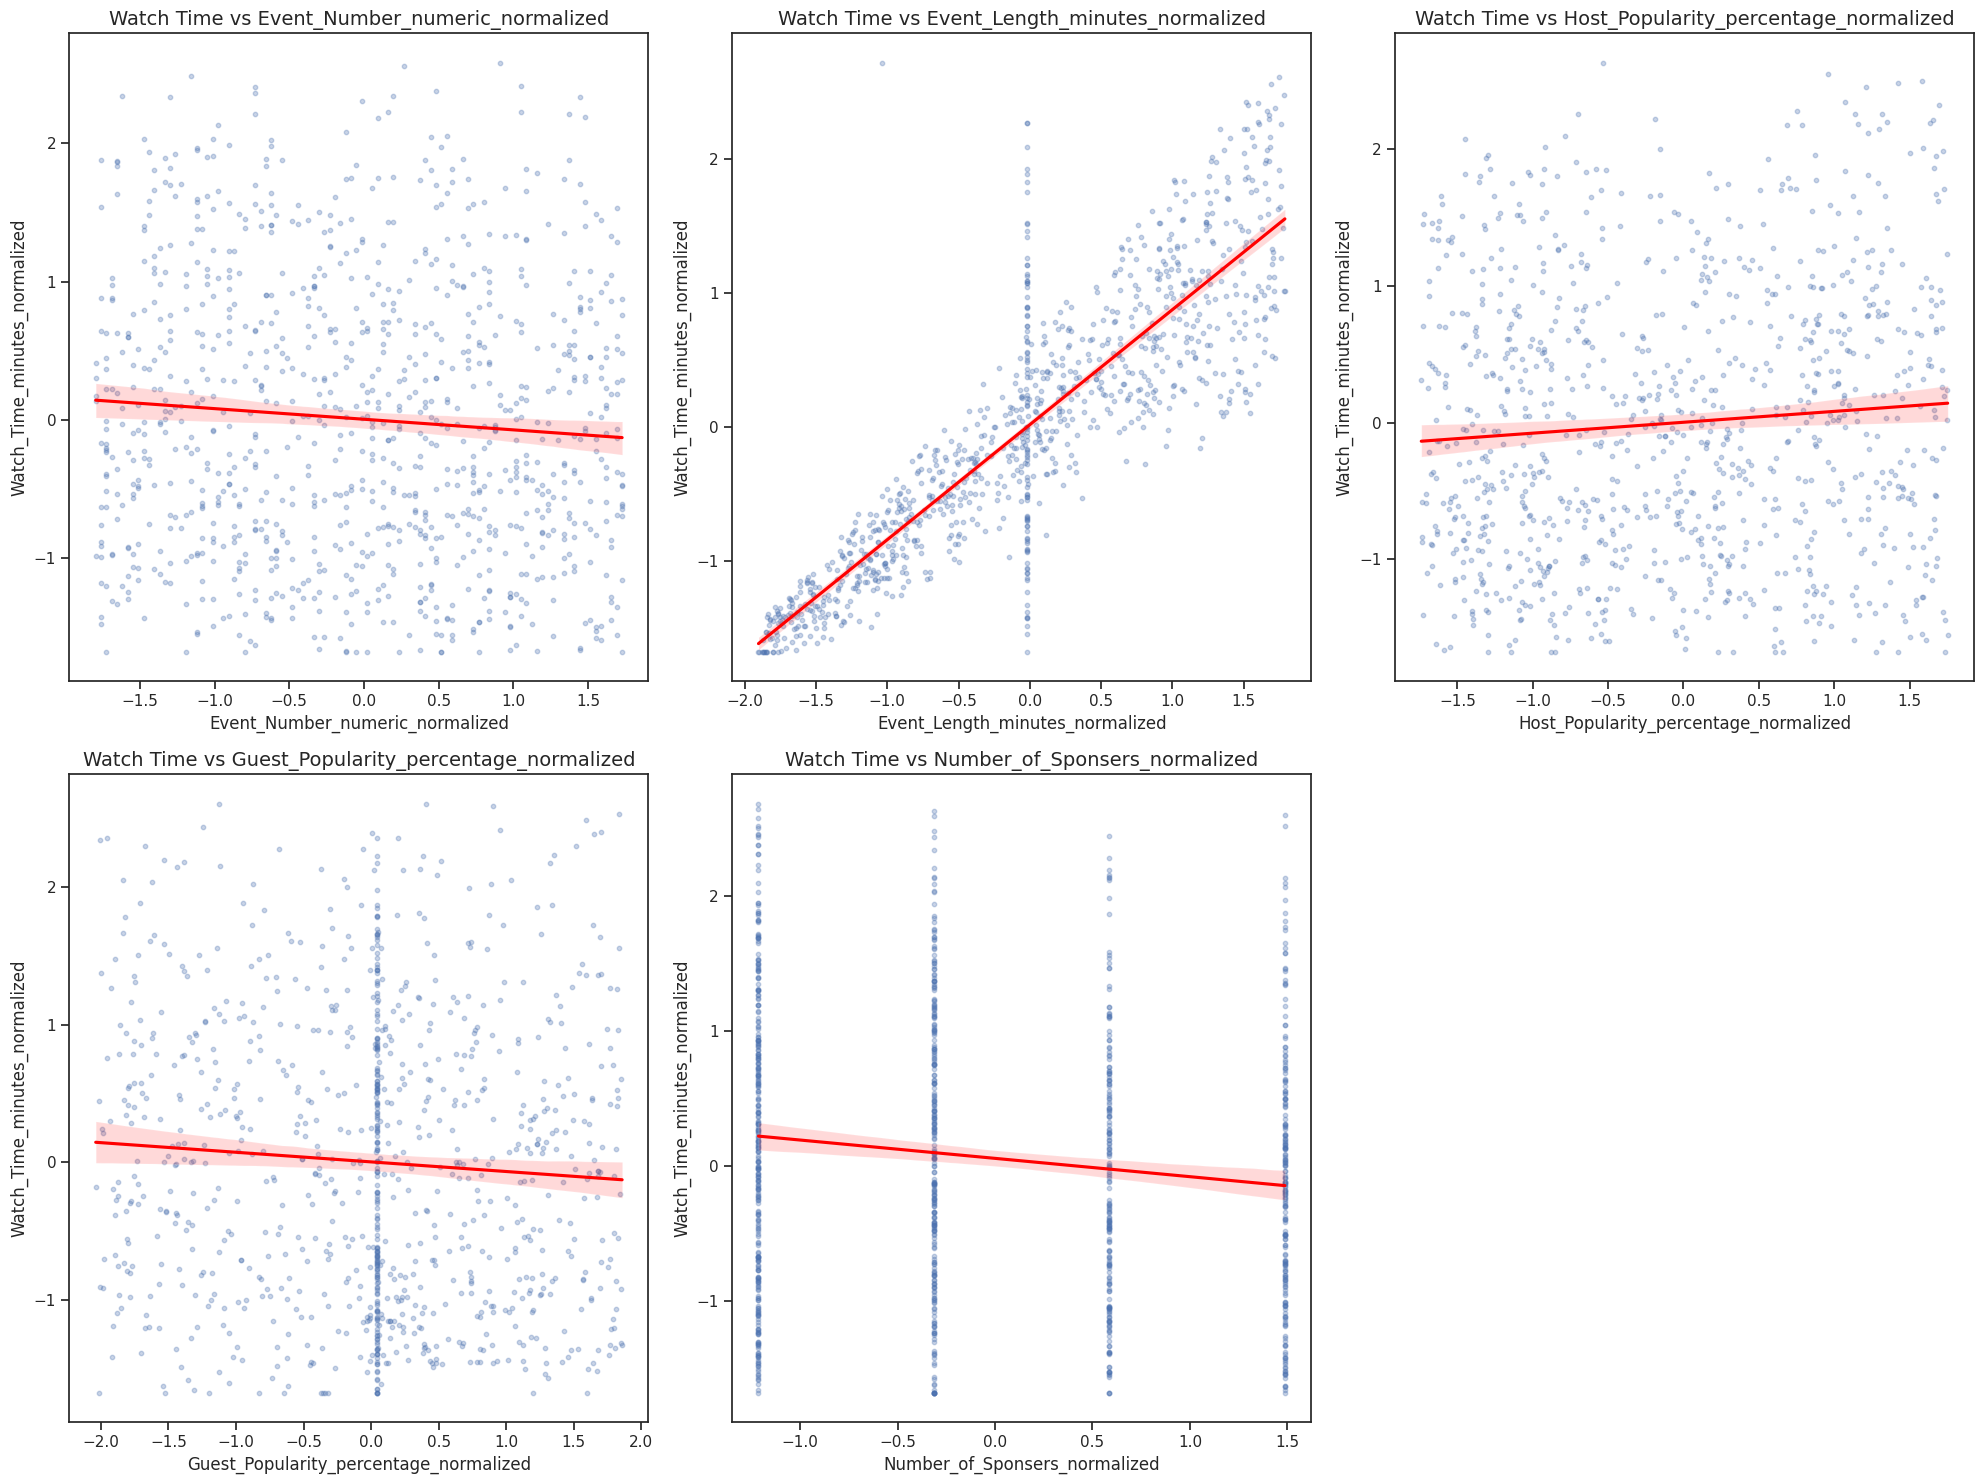

In [ ]:
num_cols = [col for col in df.columns if col.endswith('_normalized') and col != target]

plt.figure(figsize=(20, 15))
for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i+1)
    sns.regplot(data=df.sample(min(1000, len(df))), x=col, y=target,
                scatter_kws={'alpha':0.3, 's':10}, line_kws={'color':'red'})
    plt.title(f'Watch Time vs {col}', fontsize=14)

plt.tight_layout()
plt.show()

Target Variable Interaction Analysis (Watch Time)
Based on the generated visualizations, here is a professional analysis of the relationships between the features and watch time:
1. Insights from Categorical Variables (Boxplots)
- Uniformity and Representation: The median watch times are nearly identical across all categories (Genre, Event_Day, Publication_Time, and Sentiment), centered around 0. This indicates a well-balanced dataset without strong bias toward any specific category.

 - Variance Stability: The boxes across all genres and days are of similar height, suggesting future model stability—the model is unlikely to perform significantly worse on one genre compared to another.

 - Positive Sentiment: In the Event_Sentiment plot, the "Positive" category shows a slightly wider dispersion of high values, suggesting a potential for longer watch times in positive-themed content.

2. Insights from Numerical Variables (Regression Plots)
 - Dominant Predictor: The Event_Length plot shows a strong and significant positive linear correlation (the red line rises sharply with a dense point cloud). This serves as empirical proof that episode length is the most significant predictor of watch time.

 - Sponsorship Impact: The Number_of_Sponsers graph shows a very slight downward trend. This suggests that a higher number of sponsors might marginally decrease watch time—possibly due to viewer drop-off during ads—though the correlation is not severe.

 - Popularity Variables: For both the host and the guest, the regression lines are nearly flat. This is a surprising finding, indicating that participant popularity has less influence on watch time than the nature of the content itself (episode length).

 - Discrete Variable Identification: In the plots for sponsors and event numbers, the vertical "columnar" structure of the points is clearly visible, validating our decision to treat these as discrete variables.

#סיכום פרוייקט ומסקנות סופיות

Throughout this project, we conducted an end-to-end data analysis process on a dataset containing 750,000 records of podcast episodes. We began with an initial statistical analysis that revealed significant missing values in guest popularity (19%) and episode duration (11%), along with various outliers and data integrity issues. To prepare the data for analysis, we performed rigorous data cleaning, which included handling missing values using median and mean imputation, removing textual components from numerical variables (such as the prefix "Episode"), and limiting outliers using the IQR method. Subsequently, we applied Z-score normalization to all numerical variables to bring them to a uniform scale, enabling a reliable statistical comparison.

Key Research Findings:
 - The Decisive Factor for Watch Time: A very strong positive correlation (approximately 0.87) was found between episode length (Event_Length_minutes) and watch time, indicating that the audience is not deterred by long-form content.
 - Popularity vs. Content: Surprisingly, the popularity of the host or guest was found to have a very low impact on total listening time, suggesting that content quality outweighs "big names".
  - The Impact of Sentiment and Timing: Episodes with a positive sentiment achieve higher audience retention than negative ones. Additionally, publishing during evening and night hours was found to be more effective for improving watch times compared to morning hours.
   - The Negative Effect of Commercial Overexposure: A negative correlation was identified between the number of sponsors and watch time, suggesting that an excessive number of advertisements leads to listener drop-off.